<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/08_Phishing_Detection/EnsembleQML_EthereumPhishing_Ray2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classical ensembles of quantum-classical models for Ethereum phishing detection: Ray et al. (2022) step by step

This notebook re-implements, runs and checks the experiments of

> Anupama Ray, Sai Sakunthala, Vishnu Ajith and Dhinakaran Vinayagamurthy,
> "Classical ensemble of Quantum-classical ML algorithms for Phishing detection in Ethereum transaction networks",
> arXiv:2211.00004 (2022). https://arxiv.org/abs/2211.00004

**What the notebook does.** Every Ethereum account (node) is described by 7 statistics of the transaction graph (in-degree, out-degree,
degree, in-strength, out-strength, strength, number of neighbours). The notebook downloads the authors' own train and test feature files
from their public GitHub repository (pinned commit) and then rebuilds the paper's **ensemble framework**:

* the individual learners: a **quantum-kernel SVM (QSVM-qiskit)**, a **Variational Quantum Classifier (VQC)**, an **annealing QSVM**
  (SVM dual as a QUBO, solved by simulated annealing in place of the D-Wave machine) and the classical **LightGBM, RBF-SVM and random forest**;
* **two-level stacking**: base models' predicted labels are appended to the 7 features and a meta classifier is trained on them, for every
  combination of one or two base models and a meta classifier; **three-level stacking**; **bagging** of five quantum
  models with maximum voting and F1-weighted voting; plain voting as a reference;
* the **ansatz study**: 19 benchmark ansatzes x 3 feature maps (Z, ZZ, amplitude) x 1 and 2 layers, expressibility and entangling capability
  of every ansatz and their Pearson correlation with the macro precision / recall / F-score (Figures 8 to 10 of the paper);
* the **training-time scaling** of QSVM and VQC (Figure 4, small sizes only).

The last section prints the paper's numbers next to ours and gives a verdict per claim.

**How to run it.** Open it in Google Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. `FAST_MODE = True` is a sub-10-minute class demo on an unloaded machine (2,200 test nodes, 40 COBYLA iterations, one seed, a subset of the ensembles and of the ansatzes);
`FAST_MODE = False` follows the paper's budgets as far as a CPU allows (all 11,000 test nodes, 100 COBYLA iterations, 5 runs of every individual model, 57 ensembles x 2 runs, all 19 ansatzes x 2 runs). The configuration cell switches between them. **The saved run is the full one (`FAST_MODE = False`) and took 104 minutes** on a laptop CPU that was shared with about 30 other Python jobs (the FAST path took 22 minutes on the same loaded machine); on a free machine it should be several times faster. No account, token or GPU is needed: the data
come from a public GitHub repository, not from a gated Hugging Face dataset, so no Hugging Face token is involved (a gated dataset would need the
reader's own token in Colab Secrets, `HF_TOKEN`).

**What you get at the end.** Tables of macro-F1 / phishing-F1 / false positives for the individual models and for the ensembles, the circuits
that are simulated, re-drawn versions of Figures 4 to 10, and a "paper vs this notebook" verdict table.

## The paper in one page

**Problem.** Find phishing accounts in the Ethereum transaction graph. Phishing nodes are extremely rare (1,165 of about 3 million crawled
nodes, 0.039 %), so the task is an extreme class-imbalance / anomaly problem in which false positives hurt precision and missed phishing
accounts hurt recall.

**Decision.** Binary classification of one node from 7 statistics of the transaction graph (Chen et al. 2020): phishing vs not phishing.

**Method.** Individual learners: *QSVM-qiskit* (quantum kernel `K(x,y) = |<phi(x)|phi(y)>|^2`, Eq. 20 to 22), *VQC* (feature map, ansatz, parity
read-out, COBYLA, `maxiter = 100`), *QSVM-dwave* (SVM dual as a QUBO, RBF kernel with `sigma = 150`, precision vector `[2^0, 2^1]`), and classical
LightGBM, SVM and a GCN on the full graph. **Ensembles**: *stacking* (two or three levels: the predicted labels of the base models are appended to the
original features and the next level is trained on them) and *bagging* (five models of the same type, each trained on the 160 phishing nodes and
a different random set of 160 non-phishing nodes; maximum voting or a vote weighted by the phishing F1 of each model).

**Data.** Training 160 phishing + 160 non-phishing nodes, test 1,000 phishing + 10,000 non-phishing nodes ("160p-160np", "1000p-10000np"), the
authors' files. The full 3-million-node graph is not public, so the GCN and the full-scale LightGBM skyline of the paper cannot be rerun.

**Claims checked here.**

| # | Claim in the paper | Where |
|---|---|---|
| C0 | Table 1: mean and standard deviation of the 7 features for 1,160 phishing and 10,800 non-phishing nodes | Table 1 |
| C1 | Table 2 simulator rows (macro F1 / phishing F1): VQC 0.67 / 0.63; VQC + LGBM 0.86 / 0.86; QSVM-dwave (classical annealing) 0.78 / 0.74 | Table 2 |
| C2 | Stacking VQC with LGBM lifts the macro F1 by about 19 points on the simulator (0.67 to 0.86; "24 points" on the noisy 5-qubit device) | Table 2, Sec. 6 |
| C3 | Classical models are better at recall; QSVM-qiskit and VQC are weaker classifiers and so good candidates for ensembling | Fig. 5, Sec. 6 |
| C4 | QSVM-qiskit has the lowest number of false positives of the individual models; ensembles with QSVM-qiskit have the most true negatives (except with QSVM-dwave) | Fig. 7, Sec. 6 |
| C5 | The annealing QSVM has the best macro F-score among the quantum models and is the fastest to train; stacked with other models it dominates, the ensemble equals QSVM-dwave alone | Sec. 6 |
| C6 | The best ensembles all use stacking and contain at least one quantum model; ensembles improve macro F and phishing F over the individual models | Fig. 6, abstract |
| C7 | Bagging brings no significant improvement over the individual runs | Sec. 6, appendix |
| C8 | Training time: QSVM-qiskit grows about linearly with the training size, VQC much faster | Fig. 4 |
| C9 | Ansatz study: Pearson correlation of F-score with expressibility (Z -0.720, ZZ -0.713, amplitude -0.841) and with the entangling capability (von Neumann: -0.940, -0.919, -0.940); precision and F-score fall as expressibility rises, recall does not change | Figs. 8, 9 |
| C10 | Going from 1 to 2 ansatz layers lowers the macro F-score for all 19 circuits and all 3 feature maps | Fig. 10 |

Figures 5 to 7 of the paper are bar charts without printed values, so only the textual statements about them can be checked. The hardware
rows of Table 2 (ibmq_belem, ibmq_geneva, ibmq_mumbai, D-Wave 5617) and the GCN cannot be reproduced without the devices and the graph.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | Etherscan crawl of 3 M nodes, "available with the code" | the **authors' own feature files** `train_data.npy`, `train_labels.npy`, `test_data.npy`, `test_labels.npy` from github.com/anupamaray/EnsembleQML_application at a pinned commit (Apache-2.0): first 320 training rows (160 + 160) and all 11,000 test rows (1,000 + 10,000) |
| Table 2 setting | not stated; the scores (macro 0.67, phishing 0.63) imply a balanced test set | the rows are compared with random **balanced 150 + 150 subsets** of the test set (20 draws, mean); the full 1:10 test set is reported next to them (`# CHOICE`) |
| ZZ feature map | real features, settings not given | `zz_feature_map(n, reps=2, entanglement="full")` on the **raw** features, which is what the authors' notebooks do (`ZZFeatureMap(feature_dim)`) |
| VQC | feature map + `TwoLocal(['ry','rz'], 'cz', reps=2)`, COBYLA `maxiter=100`, parity read-out, mean of 5 runs | the same ansatz (`n_local`, full entanglement), COBYLA `maxiter=100`, random initial weights in [0, 1) as in Qiskit's `VQC`, 5 seeds; **parity read-out** as written in the paper, cross-entropy on the parity probabilities as in Qiskit's `VQC` (`# CHOICE`); Qiskit's own `VQC` measures only the least-significant bit (`x % 2`), which is run as an extra row |
| QSVM-qiskit | `QSVC`, ZZ map | `SVC(kernel="precomputed", C=1)` on the exact fidelity kernel, asserted equal to Qiskit's `QSVC` + `FidelityStatevectorKernel` |
| QSVM-dwave | D-Wave Advantage; RBF `sigma = 150`, precision `[1, 2]` | the identical QUBO solved by `dwave.samplers.SimulatedAnnealingSampler` (Table 2 itself lists identical scores for "classical annealing" and D-Wave) |
| Classical models | LightGBM, SVM, GCN | `LGBMClassifier`, `SVC(rbf)`, `RandomForestClassifier`; **no GCN** (needs the 3 M-node graph) |
| Stacking | predicted labels of base models (on training and test data) appended as features; "all combinations" | exactly that, in-sample predictions on the training data as in the authors' notebooks; every combination of 1 or 2 base models from {LGBM, SVM, QSVM, VQC, QSVM-dwave} and a meta classifier from {LR, LGBM, SVM, QSVM, QSVM-dwave} that is not one of its bases; a VQC meta classifier (8 or 9 qubits, very slow to train on a CPU) only for a few stacks (`# CHOICE`); an out-of-fold variant is an extra (`# CHOICE`) |
| Three-level stacking | GCN base, QSVM + LGBM level 1, LR meta | the GCN cannot be run: a classical base model stands in for it (SVM, then LGBM), the rest as in the paper (`# CHOICE`) |
| Bagging | 5 models x (160 phishing + 160 random non-phishing), max voting and F1-weighted voting | the same; the non-phishing nodes are drawn from the 800 in the training file; the weights are the phishing F1 of each model on the 960-node training file (the paper's weights seem to use test F1, shown as `[paper-literal]`) |
| Ansatzes | 19 circuits of Sim et al. 2019, 1 and 2 layers, 3 feature maps, mean of 5 runs | (2 runs here) re-implemented from the description of Fig. 2 of Sim et al. (`# CHOICE`: gate order inside an entangling block may differ from the authors' code); Z, ZZ (7 qubits) and amplitude encoding (3 qubits) |
| Expressibility / entangling capability | Sim et al.; Meyer-Wallach and von Neumann | KL divergence of the fidelity histogram (75 bins) from the Haar distribution; Meyer-Wallach `Q`; mean single-qubit von Neumann entropy in bits; sample sizes in the configuration cell |
| Hardware | IBM 5 / 27 qubits, D-Wave | not run (`cannot be checked`) |
| Seeds / runs | mean of 5 runs | `SEED = 42`; **5 runs** of every individual model in the full mode (1 in FAST_MODE); only **2 runs** of the 57 stacks, of the three-level stacks, of the bagging ensembles and of every ansatz-study configuration, and the slow 8- and 9-qubit VQC meta classifiers (`LGBM -> VQC`, `LGBM + QSVM -> VQC`) only once, to keep the run at CPU scale (`# CHOICE`) |

Install cell. Qiskit 2.x, qiskit-machine-learning 0.9 and the annealing sampler are pinned to the versions this notebook was tested with. On a
machine where they are already importable (a prepared environment) nothing is reinstalled.

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, lightgbm.
# The pip line runs on Colab (or wherever the packages are missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
_missing = [m for m in ("qiskit", "qiskit_machine_learning", "qiskit_aer", "dwave.samplers", "dimod", "lightgbm")
            if importlib.util.find_spec(m.split(".")[0]) is None]
if IN_COLAB or _missing:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc "dimod==0.12.22" "dwave-samplers==1.8.0" lightgbm
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit stack, lightgbm and dwave-samplers already present; skipping pip install.")

Qiskit stack, lightgbm and dwave-samplers already present; skipping pip install.


In [2]:
# ---------------- configuration (every tunable constant lives here) ----------------
FAST_MODE   = False    # True: class demo (< 10 min). False: the paper's budgets (COBYLA 100, 11,000 test nodes, 5 runs, 19 ansatzes, all ensembles).
SEED        = 42       # CHOICE: the paper gives no seed
IBM_TOKEN   = ""       # optional; real-hardware cells are not part of this notebook (the paper's hardware rows cannot be rerun)

DATA_DIR    = "qc314_data"                       # cache for the downloaded .npy files
REPO        = "anupamaray/EnsembleQML_application"
REPO_SHA    = "8e345c43f1b736e571dfebabe66225b32a3b4197"   # pinned commit of the authors' repository
N_TRAIN_PER_CLASS = 160                          # paper: 160 phishing + 160 non-phishing training nodes
N_TEST_FAST = 2200                               # FAST_MODE: stratified test subset (200 phishing + 2000 not)
N_BAL_DRAWS = 20                                 # random balanced 150+150 test subsets (the Table 2 comparison)

N_SEEDS     = 1 if FAST_MODE else 5              # paper: mean of 5 runs
VQC_MAXITER = 40 if FAST_MODE else 100           # COBYLA budget of every VQC (paper: maxiter = 100)
SIGMA       = 150.0                              # RBF sigma of the annealing QSVM (paper)
QA_PRECISION = (1, 2)                            # precision vector p = [2^0, 2^1] (paper)
QA_READS    = 10 if FAST_MODE else 50            # simulated-annealing restarts
QA_SWEEPS   = 1000
BASE_POOL   = ["LGBM", "SVM-rbf", "QSVM", "VQC", "QSVM-anneal"]      # base models of the two-level stacks
META_POOL   = ["LR", "LGBM", "SVM-rbf", "QSVM", "QSVM-anneal"]            # meta classifiers (a VQC meta classifier has 8 or 9 qubits and is run for the stacks below only)
VQC_META_STACKS = [("LGBM",)] if FAST_MODE else [("LGBM",), ("LGBM", "QSVM")]   # base models of the stacks that get a VQC as meta classifier
N_AUX_SEEDS = 1 if FAST_MODE else 2             # runs of the (costly) stacks, three-level stacks and bagging; the individual models use N_SEEDS
STACK_MAX_BASES = 1 if FAST_MODE else 2          # FAST: single-base stacks only; full: 1 or 2 bases
OOF_STACKS  = False if FAST_MODE else True       # extra: out-of-fold base predictions (5-fold) for every stack (first run only)
N_BAGS      = 5                                  # paper: five models per bagging ensemble
SCALE_SIZES = [40, 80, 160, 320] if FAST_MODE else [40, 80, 160, 320, 640, 960]   # training sizes of the timing study (paper: up to 20,000)
ABL_ANSATZ  = [1, 6, 9, 11, 16] if FAST_MODE else list(range(1, 20))               # ansatzes of the ablation (paper: all 19)
ABL_RUNS    = 1 if FAST_MODE else 2              # runs per (ansatz, feature map, layers); paper: mean of 5 (reduced here for CPU time)
ABL_MAXITER = 30 if FAST_MODE else 100
METRIC_PAIRS = 400 if FAST_MODE else 2000        # state pairs for expressibility / entangling capability (Sim et al. use 5000)
RUNTIME_NOTE = "see the markdown cell above the configuration"   # filled in after the saved run

In [3]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"): os.environ.setdefault(_v, "2")   # shared machine: few BLAS threads
os.environ.setdefault("QISKIT_PARALLEL", "FALSE")
import time, urllib.request, warnings, hashlib, itertools, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
from sklearn.metrics.pairwise import rbf_kernel
try:
    import lightgbm as lgb
    LGBM = lambda seed: lgb.LGBMClassifier(random_state=seed, verbose=-1, n_jobs=1)
    LGBM_NAME = "LGBM"
except Exception:                                  # CHOICE: fallback so that the notebook never stops on a missing wheel
    from sklearn.ensemble import HistGradientBoostingClassifier
    LGBM = lambda seed: HistGradientBoostingClassifier(random_state=seed)
    LGBM_NAME = "HistGB (LightGBM substitute)"

import qiskit, qiskit_machine_learning, qiskit_aer
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter, ParameterVector
from qiskit.circuit.library import zz_feature_map, z_feature_map, n_local, StatePreparation
from qiskit.quantum_info import Statevector, SparsePauliOp, Operator
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.algorithms import QSVC, VQC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
import dimod
from dwave.samplers import SimulatedAnnealingSampler

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| qiskit-aer", qiskit_aer.__version__, "| dimod", dimod.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| gradient boosting:", LGBM_NAME)
print("FAST_MODE =", FAST_MODE, "| seeds =", N_SEEDS, "| VQC maxiter =", VQC_MAXITER, "| ablation ansatzes =", len(ABL_ANSATZ),
      "| stack bases <=", STACK_MAX_BASES, "| OOF stacks =", OOF_STACKS)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2 | dimod 0.12.22
numpy 2.5.4 | pandas 3.0.6 | gradient boosting: LGBM
FAST_MODE = False | seeds = 5 | VQC maxiter = 100 | ablation ansatzes = 19 | stack bases <= 2 | OOF stacks = True


## 1. The data: the authors' Ethereum feature files

The paper's crawl is distributed with the authors' code: the `codes/` folder of their repository (pinned commit, Apache-2.0) holds
`train_data.npy` (960 x 7: the first 160 rows are phishing nodes, the next 800 are non-phishing), `test_data.npy` (11,000 x 7: 1,000 phishing
then 10,000 non-phishing) and the matching one-hot label files (`[1, 0]` = phishing, `[0, 1]` = not). Their stacking notebooks take the first
320 training rows (160 phishing + 160 non-phishing) to keep the training set balanced, matching the paper's "160p-160np"; we do the same.
The cell downloads the files (raw.githubusercontent.com with jsDelivr and github.com mirrors as fallbacks), caches them in `DATA_DIR` and
also accepts files you place there yourself.

The 7 features are statistics of the directed transaction multigraph: **in-degree / out-degree / degree** (number of incoming / outgoing / all
transactions), **in-strength / out-strength / strength** (ether received / sent / total) and the **number of distinct neighbours**.
The full transaction graph (about 3 million nodes) is not public, so the GCN that the paper uses as its classical state of the art, and the
2.4-million-node LightGBM skyline, cannot be rerun.

In [4]:
FEATURES = ["in_degree", "out_degree", "degree", "in_strength", "out_strength", "strength", "n_neighbors"]
FILES = ["train_data.npy", "train_labels.npy", "test_data.npy", "test_labels.npy"]
MIRRORS = [f"https://raw.githubusercontent.com/{REPO}/{REPO_SHA}/codes/{{f}}",
           f"https://cdn.jsdelivr.net/gh/{REPO}@{REPO_SHA}/codes/{{f}}",
           f"https://github.com/{REPO}/raw/{REPO_SHA}/codes/{{f}}"]

def fetch(fname):
    path = os.path.join(DATA_DIR, fname)
    if os.path.exists(path) and os.path.getsize(path) > 1000:
        return path
    last = None
    for tpl in MIRRORS:
        try:
            urllib.request.urlretrieve(tpl.format(f=fname), path)
            if os.path.getsize(path) > 1000:
                return path
        except Exception as e:
            last = e
    raise RuntimeError(f"could not download {fname} ({last}); place the four .npy files from {REPO}/codes in {DATA_DIR}/")

raw = {f: np.load(fetch(f)) for f in FILES}
for f, a in raw.items():
    print(f"{f:18s} shape={a.shape} dtype={a.dtype} sha256={hashlib.sha256(open(os.path.join(DATA_DIR, f), 'rb').read()).hexdigest()[:12]}")

# one-hot labels: column 0 == 1 means phishing (first 160 training rows / first 1000 test rows)
LABEL_NAMES = {0: "non-phishing", 1: "phishing"}
Xfile_tr, yfile_tr = raw["train_data.npy"].astype(np.float64), raw["train_labels.npy"][:, 0]    # 960 training-file nodes (160 + 800)
Xte_all, yte_all = raw["test_data.npy"].astype(np.float64), raw["test_labels.npy"][:, 0]        # 11,000 test nodes (1,000 + 10,000)
assert yfile_tr[:160].all() and not yfile_tr[160:].any() and yte_all[:1000].all() and not yte_all[1000:].any()

# training set exactly as in the authors' notebooks: first 320 rows = 160 phishing + 160 non-phishing
X_tr, y_tr = Xfile_tr[:2 * N_TRAIN_PER_CLASS], yfile_tr[:2 * N_TRAIN_PER_CLASS]
assert y_tr[:160].all() and not y_tr[160:320].any()

# FAST_MODE evaluates on a stratified subset of the test set; the full run uses all 11,000 nodes
if FAST_MODE:
    r = np.random.default_rng(SEED)
    sel = np.sort(np.r_[r.choice(1000, N_TEST_FAST // 11, replace=False), 1000 + r.choice(10000, N_TEST_FAST - N_TEST_FAST // 11, replace=False)])
else:
    sel = np.arange(len(yte_all))
X_te, y_te = Xte_all[sel], yte_all[sel]

# random balanced 150+150 subsets of the test set: the analogue of the 300-node sets behind Table 2
BAL_DRAWS = []
for d in range(N_BAL_DRAWS):
    r = np.random.default_rng(SEED + d)
    BAL_DRAWS.append(np.r_[r.choice(np.flatnonzero(y_te == 1), 150, replace=False), r.choice(np.flatnonzero(y_te == 0), 150, replace=False)])
print(f"\ntrain used: {X_tr.shape}, phishing={int(y_tr.sum())}, non-phishing={int((1 - y_tr).sum())}   (training file: {Xfile_tr.shape})")
print(f"test used : {X_te.shape}, phishing={int(y_te.sum())}, non-phishing={int((1 - y_te).sum())}  (FAST_MODE={FAST_MODE})")

train_data.npy     shape=(960, 7) dtype=float32 sha256=bfffe5f1c1ff
train_labels.npy   shape=(960, 2) dtype=int64 sha256=5ec2a32563fc
test_data.npy      shape=(11000, 7) dtype=float32 sha256=be9b15ab58ba
test_labels.npy    shape=(11000, 2) dtype=int64 sha256=c24809b1f959

train used: (320, 7), phishing=160, non-phishing=160   (training file: (960, 7))
test used : (11000, 7), phishing=1000, non-phishing=10000  (FAST_MODE=False)


## Dataset Exploration and Visualisation

Everything below uses the **real observations** of the authors' files: no data are simulated or invented. The labels are binary
(phishing / non-phishing); the data set has no finer attack families. The plots show (a) the class balance of the training and test sets,
(b) the per-class feature statistics, including a check of **Table 1** of the paper (claim C0), and (c) a 2-D PCA view of the real nodes
coloured by their ground-truth label, first as raw PCA coordinates (fitted on the training split only) and then rescaled to the angle range
[0, pi] that an angle-encoding feature map would use.

Training set: (320, 7) | test set: (11000, 7) | features: ['in_degree', 'out_degree', 'degree', 'in_strength', 'out_strength', 'strength', 'n_neighbors']
Original label files are one-hot ([1, 0] = phishing, [0, 1] = non-phishing); decoded values: [(0, 'non-phishing'), (1, 'phishing')]


,train (320 used),train file (960),test (used),"test file (11,000)"
non-phishing,160,800,10000,10000
phishing,160,160,1000,1000


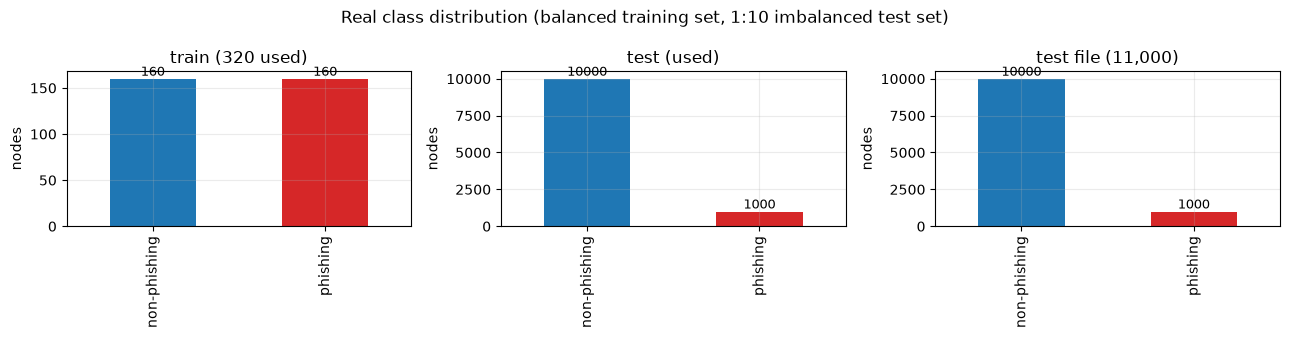

In [5]:
# ---- (a) shape, feature names, original label values, class counts, bar chart ----
print("Training set:", X_tr.shape, "| test set:", X_te.shape, "| features:", FEATURES)
print("Original label files are one-hot ([1, 0] = phishing, [0, 1] = non-phishing); decoded values:", sorted(LABEL_NAMES.items()))
cnt = pd.DataFrame({
    "train (320 used)":   pd.Series(y_tr).map(LABEL_NAMES).value_counts(),
    "train file (960)":   pd.Series(yfile_tr).map(LABEL_NAMES).value_counts(),
    "test (used)":        pd.Series(y_te).map(LABEL_NAMES).value_counts(),
    "test file (11,000)": pd.Series(yte_all).map(LABEL_NAMES).value_counts()})
display(cnt)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, col in zip(ax, ["train (320 used)", "test (used)", "test file (11,000)"]):
    cnt[col].reindex(["non-phishing", "phishing"]).plot.bar(ax=a, color=["tab:blue", "tab:red"])
    a.set_title(col); a.set_ylabel("nodes")
    for p in a.patches: a.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.suptitle("Real class distribution (balanced training set, 1:10 imbalanced test set)"); plt.tight_layout(); plt.show()

In [6]:
# ---- (b) per-class feature statistics of the real nodes, and the check of Table 1 of the paper ----
# Table 1 uses 1,160 phishing and 10,800 non-phishing nodes: the 160 + 800 nodes of the training file plus the 1,000 + 10,000 of the test file.
allX = np.vstack([Xfile_tr, Xte_all]); ally = np.r_[yfile_tr, yte_all]
assert (ally == 1).sum() == 1160 and (ally == 0).sum() == 10800
PAPER_T1 = {  # statistic: (phishing, non-phishing) per feature, paper Table 1 (order of FEATURES)
    "mean":  ([31.3956, 20.4905, 51.8862, 78.6105, 86.7360, 165.3465, 31.6965], [4.5020, 4.6438, 9.1459, 72.5328, 9.2551, 81.7880, 3.6427]),
    "std":   ([180.9905, 96.8388, 219.7376, 691.2912, 860.1017, 1390.3580, 106.3907], [154.3505, 101.3266, 192.2051, 4409.6850, 281.0234, 4421.5425, 79.3607])}
rows = []
for stat in ("mean", "std"):
    for ci, cname in ((1, "phishing"), (0, "non-phishing")):
        mine = allX[ally == ci].mean(0) if stat == "mean" else allX[ally == ci].std(0, ddof=1)
        paper = np.array(PAPER_T1[stat][0 if ci == 1 else 1])
        for f, pv, mv in zip(FEATURES, paper, mine):
            rows.append({"statistic": stat, "class": cname, "feature": f, "paper": pv, "notebook": round(float(mv), 4), "rel. diff": abs(mv - pv) / abs(pv)})
T1 = pd.DataFrame(rows)
display(T1.pivot_table(index="feature", columns=["statistic", "class"], values="notebook", sort=False).round(2))
print(f"Table 1 check: largest relative difference over {len(T1)} numbers = {T1['rel. diff'].max():.2e}; "
      f"{int((T1['rel. diff'] < 1e-3).sum())} of {len(T1)} agree to 0.1 %")

statistic        mean                   std             
class        phishing non-phishing phishing non-phishing
feature                                                 
in_degree       31.40         4.50   181.07       154.36
out_degree      20.49         4.64    96.88       101.33
degree          51.89         9.15   219.83       192.21
in_strength     78.61        72.53   691.59      4409.89
out_strength    86.74         9.26   860.47       281.04
strength       165.35        81.79  1390.96      4421.75
n_neighbors     31.70         3.64   106.44        79.36

Table 1 check: largest relative difference over 28 numbers = 4.32e-04; 28 of 28 agree to 0.1 %


PCA explained variance ratio (train fit): [0.736 0.132]


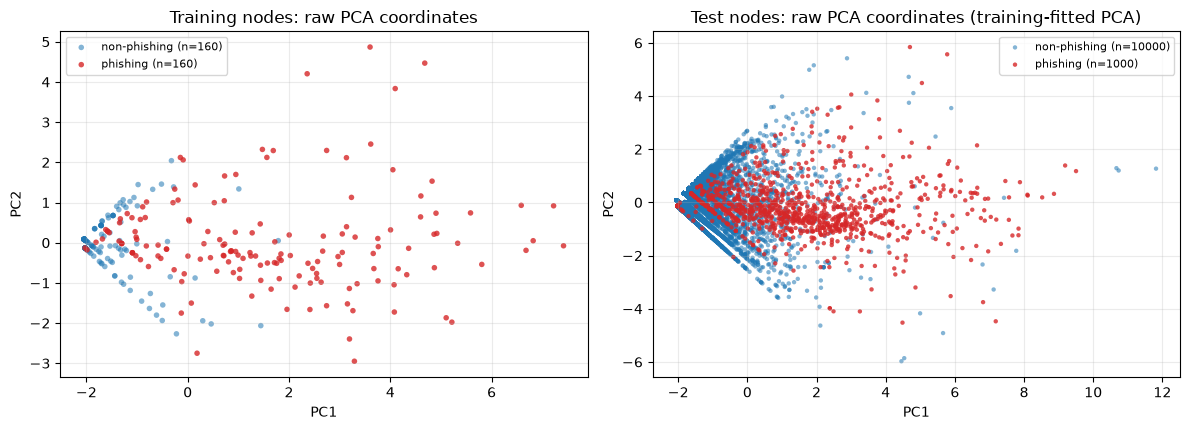

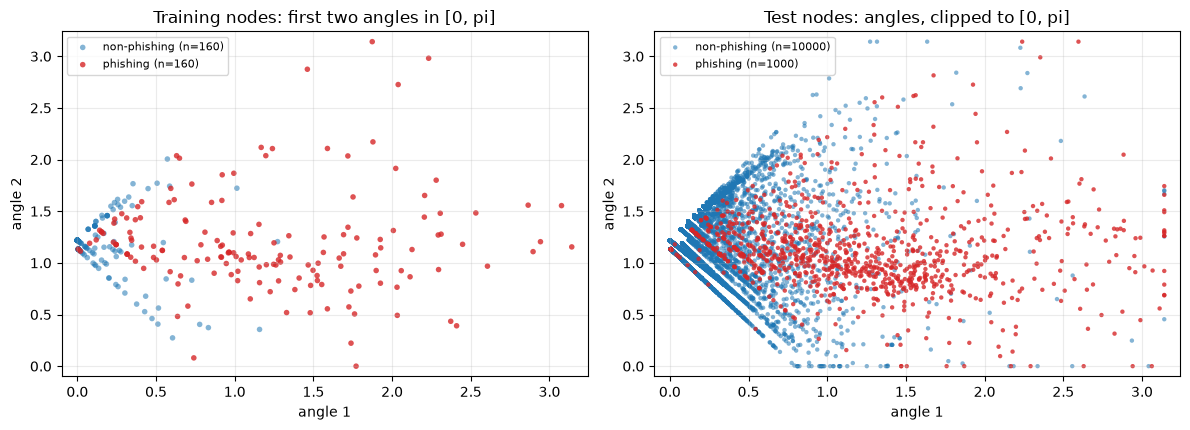

In [7]:
# ---- (c) 2-D scatter of real nodes coloured by ground truth: raw PCA coordinates, then angles in [0, pi] ----
# CHOICE: log1p first (degrees and strengths span 5 orders of magnitude); every transform is fitted on the training split only.
sc_pca = StandardScaler().fit(np.log1p(X_tr)); pca2 = PCA(n_components=2, random_state=SEED).fit(sc_pca.transform(np.log1p(X_tr)))
P_tr = pca2.transform(sc_pca.transform(np.log1p(X_tr))); P_te = pca2.transform(sc_pca.transform(np.log1p(X_te)))
ang = MinMaxScaler((0, np.pi)).fit(P_tr)
A_tr = ang.transform(P_tr); A_te = np.clip(ang.transform(P_te), 0, np.pi)
print("PCA explained variance ratio (train fit):", pca2.explained_variance_ratio_.round(3))

COL = {0: "tab:blue", 1: "tab:red"}
def scatter(ax, P, y, title, xl, yl, s=10):
    for c in (0, 1):
        m = y == c
        ax.scatter(P[m, 0], P[m, 1], s=s, c=COL[c], alpha=0.55 if c == 0 else 0.8, label=f"{LABEL_NAMES[c]} (n={int(m.sum())})", edgecolors="none")
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(fontsize=8)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
scatter(ax[0], P_tr, y_tr, "Training nodes: raw PCA coordinates", "PC1", "PC2", s=16)
scatter(ax[1], P_te, y_te, "Test nodes: raw PCA coordinates (training-fitted PCA)", "PC1", "PC2")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
scatter(ax[0], A_tr, y_tr, "Training nodes: first two angles in [0, pi]", "angle 1", "angle 2", s=16)
scatter(ax[1], A_te, y_te, "Test nodes: angles, clipped to [0, pi]", "angle 1", "angle 2")
for a in ax: a.set_xlim(-0.1, np.pi + 0.1); a.set_ylim(-0.1, np.pi + 0.1)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The paper uses two gate-based quantum models, and both are built from the **ZZ feature map** on raw features:

* **QSVM-qiskit**: the kernel circuit is the compute-uncompute circuit `phi(x_j)^dagger phi(x_i)` of Eq. 20 to 22; the kernel entry is the probability of
  measuring all zeros. It has no trainable parameters.
* **VQC**: `ZZ feature map -> TwoLocal(['ry','rz'], 'cz', reps=2) ansatz -> measurement`, read out by the parity of the measured bit string
  (even parity = phishing). The same architecture is also used as a *meta* classifier in the stacks, where the appended base-model labels
  are extra features and hence extra qubits: **7, 8 or 9 qubits** (7 features plus 0, 1 or 2 appended labels).
* **Ansatz study**: 19 benchmark ansatzes (Sim et al. 2019) with the Z feature map (7 qubits), the ZZ feature map (7 qubits) and amplitude
  encoding (7 features padded to 8 amplitudes, 3 qubits).

The annealing QSVM is a QUBO solved by simulated annealing, not a gate circuit, so it has no drawing (Section 5).

The circuits below are the objects whose behaviour is simulated later. Training a VQC with Qiskit's primitives costs seconds per evaluation, and the
study needs thousands of fits, so Section 3 uses an exact NumPy state-vector simulator that executes **the gate list of these very circuits**,
and **asserts equality** with Qiskit (`Operator`, `Statevector`, `FidelityStatevectorKernel`/`QSVC`, and Qiskit's own `VQC`) before any result is used.

**Assumptions where the paper omits circuit details**: the ZZ-map repetitions (2) and entanglement (`full`) are the Qiskit defaults used by the authors'
notebooks; the ansatz is the authors' `TwoLocal(['ry','rz'], 'cz', reps=2)` with full entanglement and a final rotation layer; the exact form of the 19
benchmark ansatzes (Sim et al. 2019, Fig. 2) is re-implemented from the published description and may differ in gate order from the authors' code;
amplitude encoding of 7 padded features uses a state-preparation block.

In [8]:
# ---------------- ansatzes: the main one of the paper and the 19 benchmark circuits of Sim, Johnson, Aspuru-Guzik (2019) ----------------
def main_ansatz(n):
    return n_local(n, ["ry", "rz"], "cz", entanglement="full", reps=2, parameter_prefix="w")   # authors' TwoLocal(['ry','rz'],'cz',reps=2)

def plist(ans):
    return list(getattr(ans, "_plist", None) or ans.parameters)

# CHOICE: re-implemented from the published description of Fig. 2 of Sim et al.; `layers` repeats the block with fresh parameters.
def sim_ansatz(k, n, layers=1):
    qc = QuantumCircuit(n, name=f"ansatz {k}"); P = []
    def par():
        p = Parameter(f"w{len(P):03d}"); P.append(p); return p
    def rot(gates, qubits=None):
        for q in (range(n) if qubits is None else qubits):
            for g in gates: getattr(qc, g)(par(), q)
    two = {"cx": lambda c, t: qc.cx(c, t), "cz": lambda c, t: qc.cz(c, t), "crz": lambda c, t: qc.crz(par(), c, t), "crx": lambda c, t: qc.crx(par(), c, t)}
    def ladder(g):
        for i in reversed(range(n - 1)): two[g](i + 1, i)
    def ring(g, shift=False):
        order = [(i, (i + 1) % n) for i in reversed(range(n))] if not shift else [(i, (i - 1) % n) for i in reversed(range(n))]
        for c, t in order:
            if c != t: two[g](c, t)
    def alltoall(g):
        for i in reversed(range(n)):
            for j in reversed(range(n)):
                if i != j: two[g](i, j)
    def brick(g, parity):
        for i in range(parity, n - 1, 2): two[g](i, i + 1)
    inner = list(range(1, n - 1))
    for _ in range(layers):
        if k == 1: rot(["rx", "rz"])
        elif k in (2, 3, 4): rot(["rx", "rz"]); ladder({2: "cx", 3: "crz", 4: "crx"}[k])
        elif k in (5, 6): rot(["rx", "rz"]); alltoall({5: "crz", 6: "crx"}[k]); rot(["rx", "rz"])
        elif k in (7, 8): g = {7: "crz", 8: "crx"}[k]; rot(["rx", "rz"]); brick(g, 0); rot(["rx", "rz"]); brick(g, 1)
        elif k == 9: [qc.h(q) for q in range(n)]; ladder("cz"); rot(["rx"])
        elif k == 10: rot(["ry"]); ring("cz"); rot(["ry"])
        elif k in (11, 12): g = {11: "cx", 12: "cz"}[k]; rot(["ry", "rz"]); brick(g, 0); rot(["ry", "rz"], inner); brick(g, 1)
        elif k in (13, 14): g = {13: "crz", 14: "crx"}[k]; rot(["ry"]); ring(g); rot(["ry"]); ring(g, shift=True)
        elif k == 15: rot(["ry"]); ring("cx"); rot(["ry"]); ring("cx", shift=True)
        elif k in (16, 17): g = {16: "crz", 17: "crx"}[k]; rot(["rx", "rz"]); brick(g, 0); rot(["rx", "rz"], inner); brick(g, 1)
        elif k in (18, 19): rot(["rx", "rz"]); ring({18: "crz", 19: "crx"}[k])
        else: raise ValueError(k)
    qc._plist = P
    return qc

def feature_map(name, n):
    """ZZ / Z feature maps of the paper (symbolic inputs x)."""
    if name == "ZZ": return zz_feature_map(n, reps=2, entanglement="full", parameter_prefix="x")
    if name == "Z":  return z_feature_map(n, reps=2, parameter_prefix="x")
    raise ValueError(name)

def deco(c, reps=3):
    for _ in range(reps): c = c.decompose()
    return c

rows = []
for n in (7, 8, 9):
    fm, ans = feature_map("ZZ", n), main_ansatz(n)
    kc = fm.compose(fm.inverse()); vq = QuantumCircuit(n); vq.compose(fm, inplace=True); vq.compose(ans, inplace=True)
    dv = deco(vq)
    rows.append({"model": f"ZZ feature map + TwoLocal(ry,rz;cz;reps=2), {n} qubits", "qubits": n, "input angles": fm.num_parameters, "trainable weights": len(plist(ans)),
                 "depth (VQC)": dv.depth(), "2-qubit gates (VQC)": dv.count_ops().get("cx", 0) + dv.count_ops().get("cz", 0),
                 "depth (QSVM kernel circuit)": deco(kc).depth(), "kernel-circuit parameters": 0})
print("Circuits of the paper's models (7 qubits = the 7 features; 8 and 9 qubits = stacks that append one or two base-model labels as extra features):")
display(pd.DataFrame(rows).set_index("model"))

Circuits of the paper's models (7 qubits = the 7 features; 8 and 9 qubits = stacks that append one or two base-model labels as extra features):


,qubits,input angles,trainable weights,depth (VQC),2-qubit gates (VQC),depth (QSVM kernel circuit),kernel-circuit parameters
model,,,,,,,
"ZZ feature map + TwoLocal(ry,rz;cz;reps=2), 7 qubits",7,7,42,101,126,116,0
"ZZ feature map + TwoLocal(ry,rz;cz;reps=2), 8 qubits",8,8,48,116,168,134,0
"ZZ feature map + TwoLocal(ry,rz;cz;reps=2), 9 qubits",9,9,54,131,216,152,0


QSVM kernel circuit (ZZ map, 7 qubits) for two training nodes: qubits=7, depth=117, trainable parameters=0 (the kernel is non-parametric)


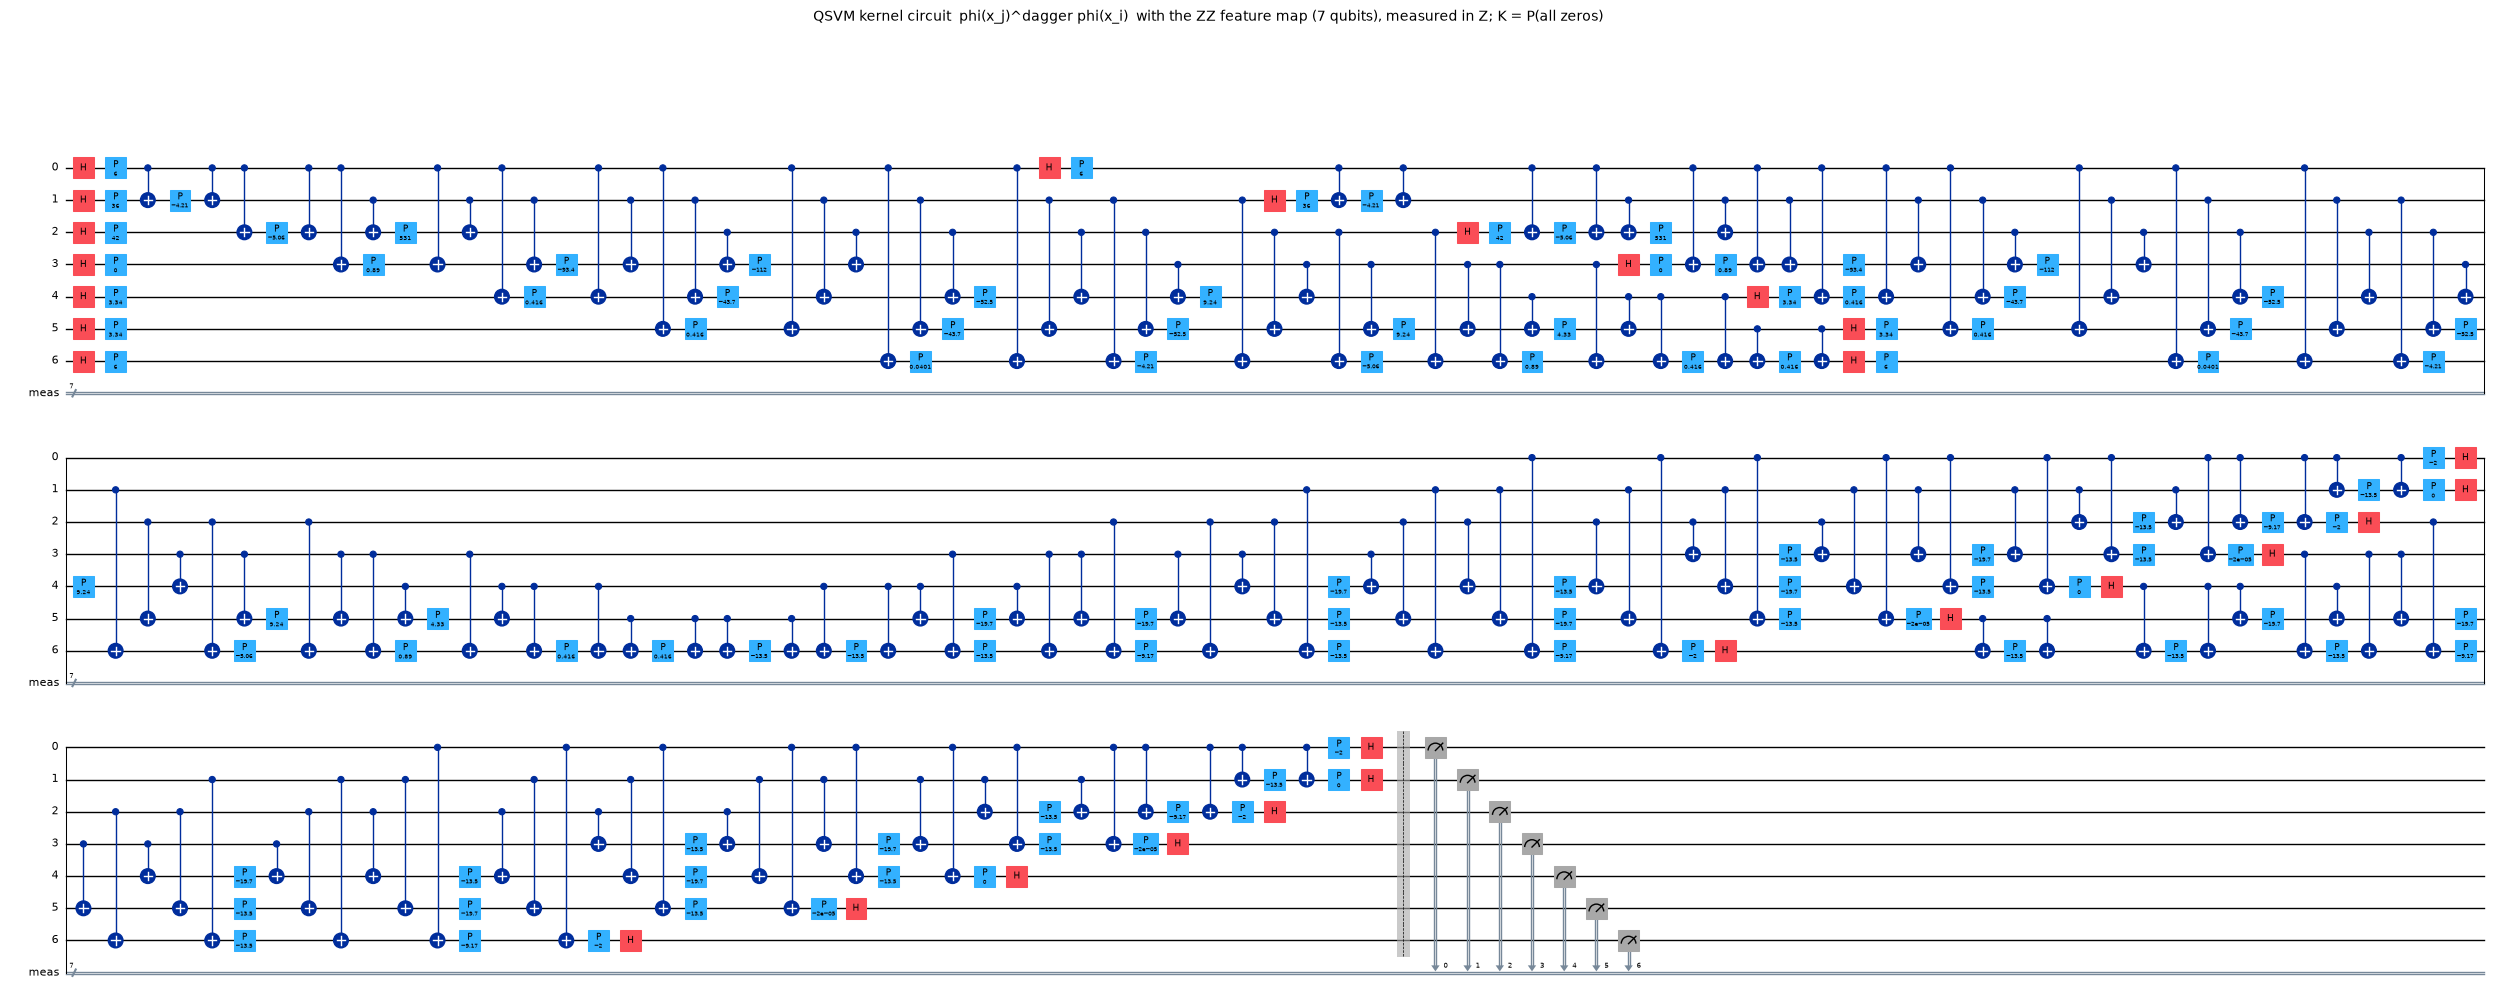

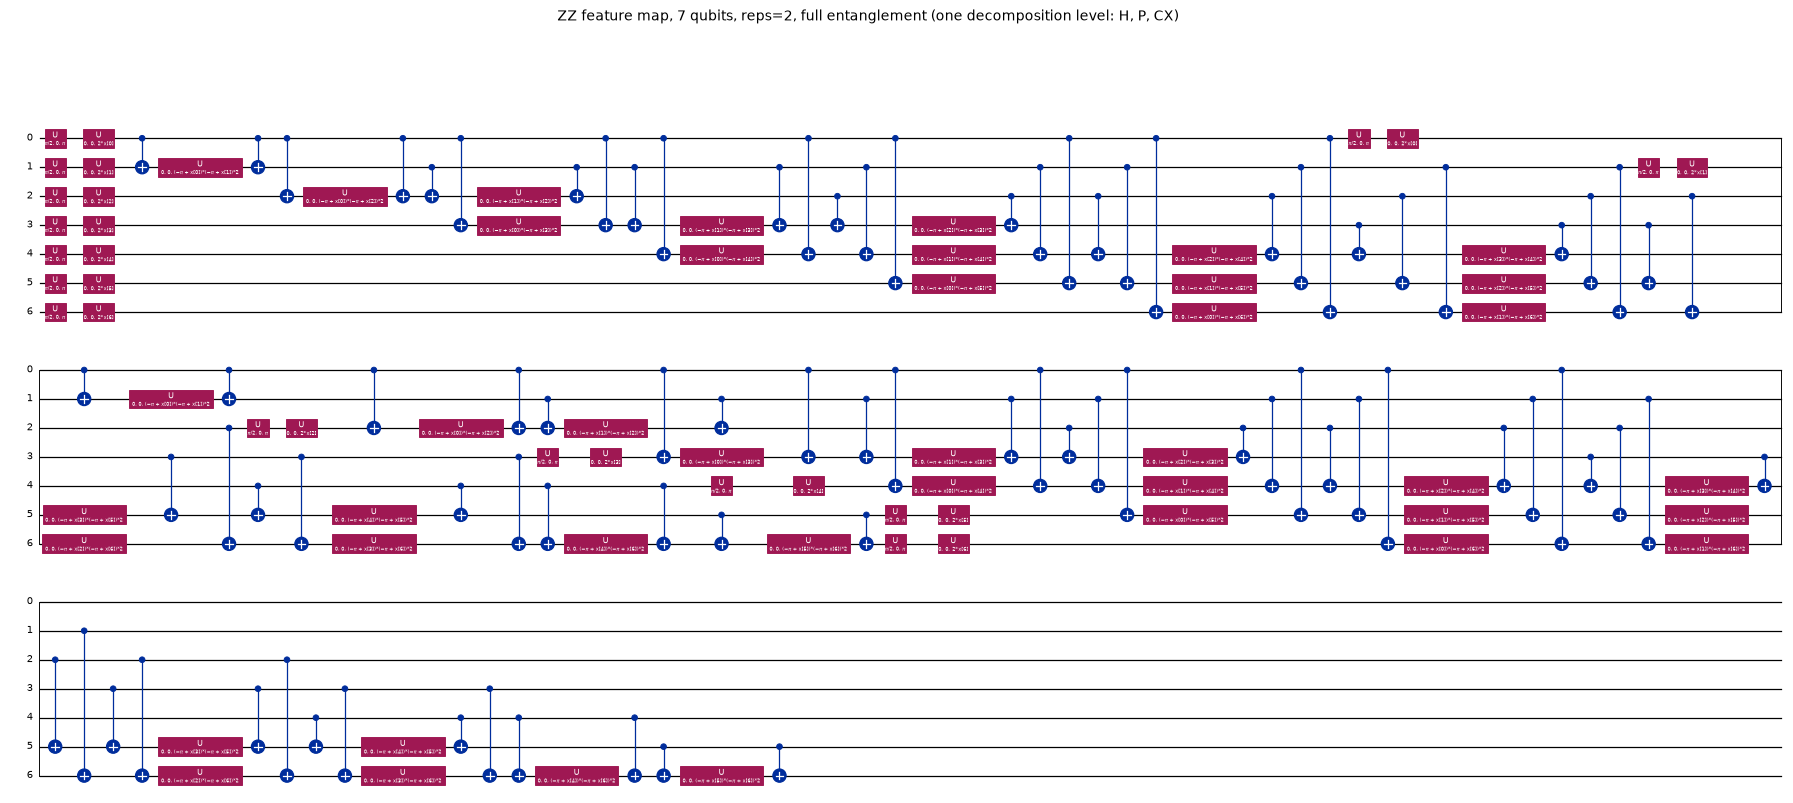

VQC with 7 qubits: depth(decomposed)=102 | input angles=7 | trainable weights=42 | 2-qubit gates (ansatz)=42


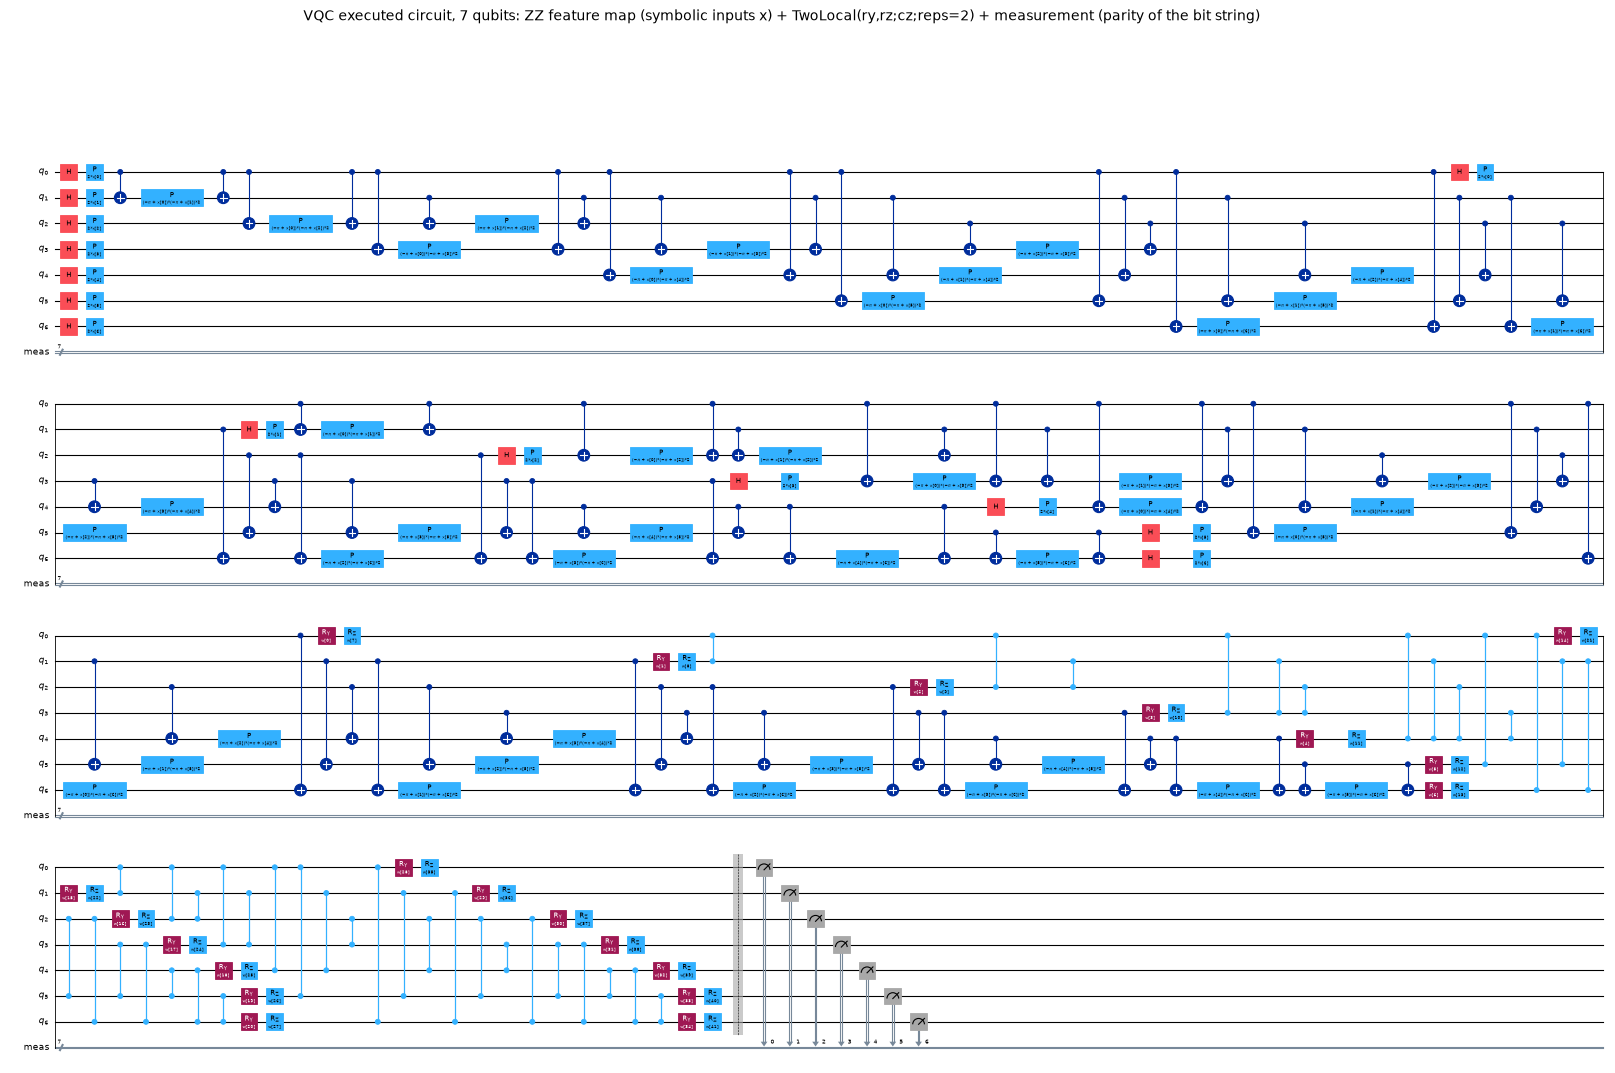

VQC with 8 qubits: depth(decomposed)=117 | input angles=8 | trainable weights=48 | 2-qubit gates (ansatz)=56


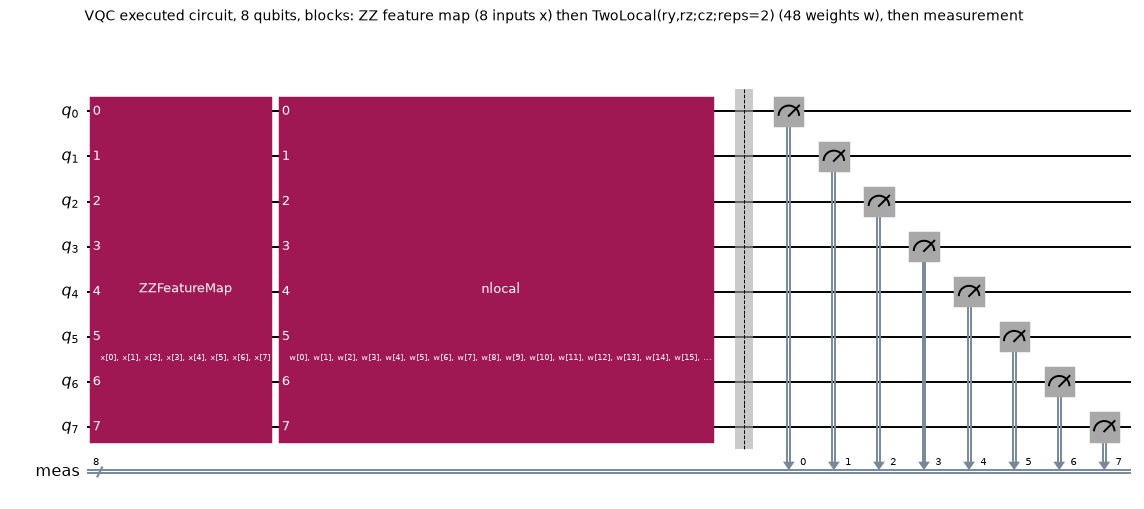

VQC with 9 qubits: depth(decomposed)=132 | input angles=9 | trainable weights=54 | 2-qubit gates (ansatz)=72


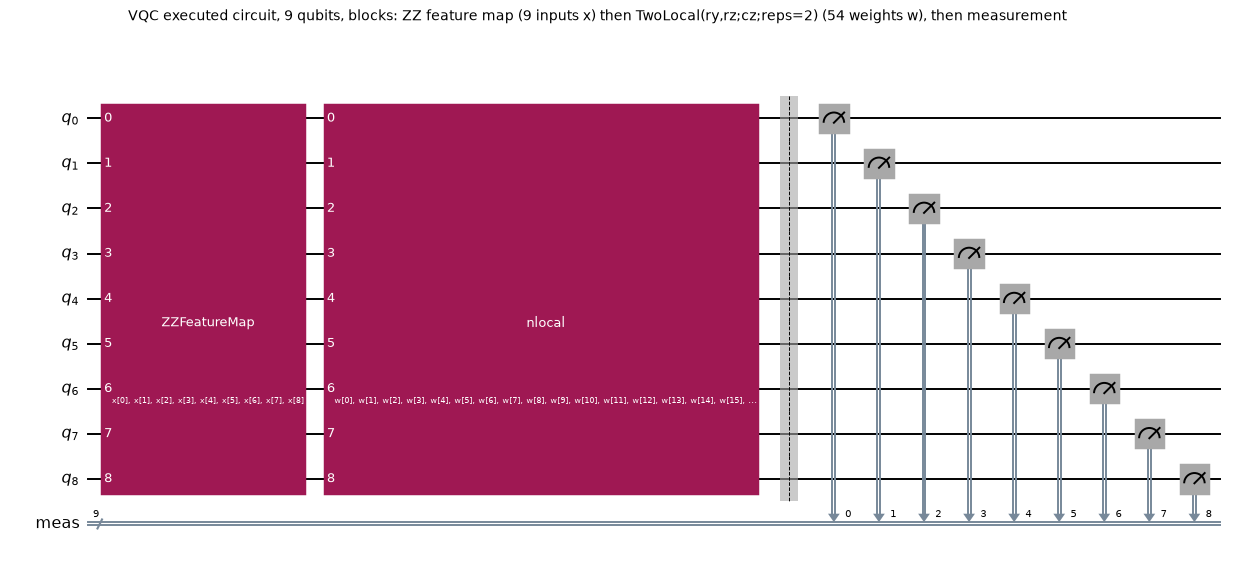

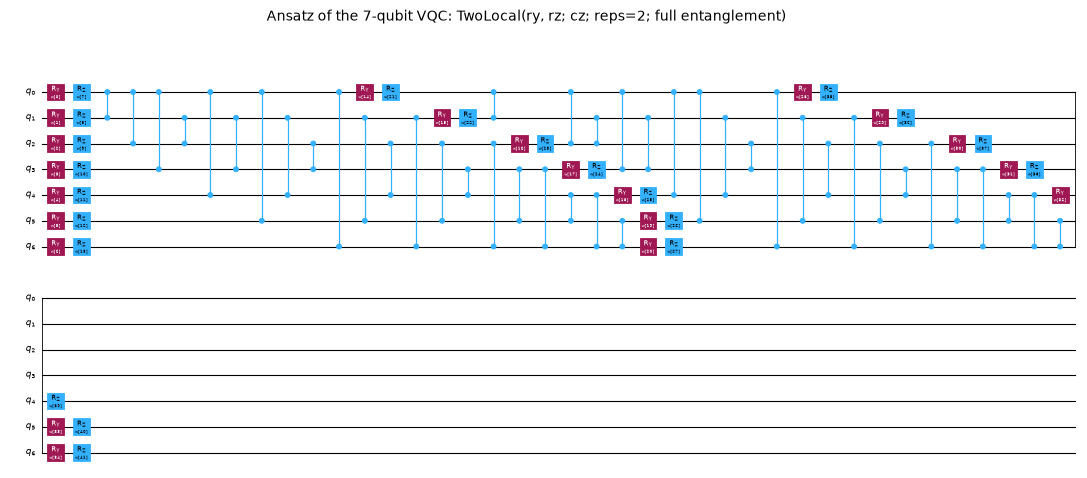

In [9]:
def show_circuit(c, title, **kw):
    fig = c.draw("mpl", **kw); fig.suptitle(title, fontsize=10, y=1.0); display(fig); plt.close(fig)

# ---- QSVM kernel circuit (compute-uncompute), drawn from the object whose kernel is computed below ----
fm7 = feature_map("ZZ", 7)
xa, xb = X_tr[0], X_tr[200]
kc = fm7.assign_parameters(xa).compose(fm7.assign_parameters(xb).inverse()); kc.measure_all()
print(f"QSVM kernel circuit (ZZ map, 7 qubits) for two training nodes: qubits={kc.num_qubits}, depth={deco(kc).depth()}, trainable parameters=0 (the kernel is non-parametric)")
show_circuit(kc, "QSVM kernel circuit  phi(x_j)^dagger phi(x_i)  with the ZZ feature map (7 qubits), measured in Z; K = P(all zeros)", fold=75, scale=0.5)
show_circuit(fm7.decompose(), "ZZ feature map, 7 qubits, reps=2, full entanglement (one decomposition level: H, P, CX)", fold=60, scale=0.45)

# ---- VQC circuits: 7 qubits (base model, fully expanded), 8 and 9 qubits (meta model with 1 or 2 appended labels; feature map and ansatz drawn as blocks) ----
for n in (7, 8, 9):
    fm, ans = feature_map("ZZ", n), main_ansatz(n)
    qc = QuantumCircuit(n); qc.compose(fm, inplace=True); qc.compose(ans, inplace=True); qc.measure_all()
    print(f"VQC with {n} qubits: depth(decomposed)={deco(qc).depth()} | input angles={fm.num_parameters} | trainable weights={len(plist(ans))} | "
          f"2-qubit gates (ansatz)={ans.count_ops().get('cz', 0)}")
    if n == 7:
        show_circuit(qc, "VQC executed circuit, 7 qubits: ZZ feature map (symbolic inputs x) + TwoLocal(ry,rz;cz;reps=2) + measurement (parity of the bit string)", fold=60, scale=0.4)
    else:
        qb = QuantumCircuit(n); qb.append(fm.to_instruction(), range(n)); qb.append(ans.to_instruction(), range(n)); qb.measure_all()
        show_circuit(qb, f"VQC executed circuit, {n} qubits, blocks: ZZ feature map ({n} inputs x) then TwoLocal(ry,rz;cz;reps=2) ({len(plist(ans))} weights w), then measurement", fold=-1, scale=0.7)
show_circuit(main_ansatz(7), "Ansatz of the 7-qubit VQC: TwoLocal(ry, rz; cz; reps=2; full entanglement)", fold=40, scale=0.4)

Z feature map: qubits=7, input angles=7, depth(decomposed)=4, no entangling gates


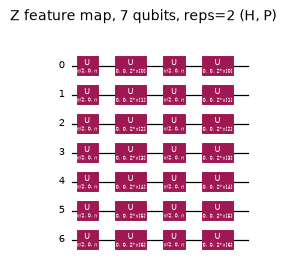

Amplitude encoding: 7 raw features padded to 8 amplitudes -> 3 qubits; the state-preparation circuit really prepares the normalised amplitudes (asserted)


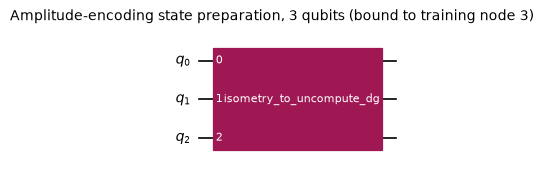

ansatz,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
"params (3 q, 1 layer)",6,6,8,8,18,18,14,14,3,6,8,8,12,12,6,10,10,9,9
"params (7 q, 1 layer)",14,14,20,20,70,70,34,34,7,14,24,24,28,28,14,30,30,21,21
"params (7 q, 2 layers)",28,28,40,40,140,140,68,68,14,28,48,48,56,56,28,60,60,42,42
depth (3 q),2,4,9,13,24,28,11,15,7,9,6,9,24,32,8,11,15,14,16
2-qubit gates (7 q),0,6,6,6,42,42,6,6,6,7,6,6,14,14,14,6,6,7,7


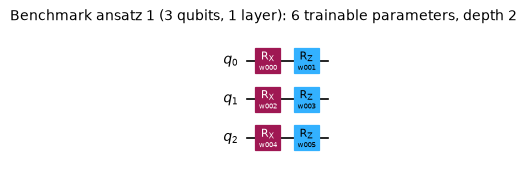

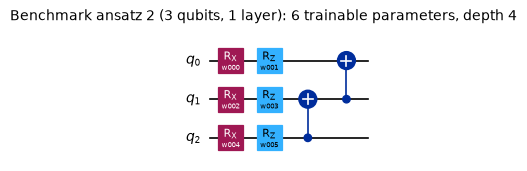

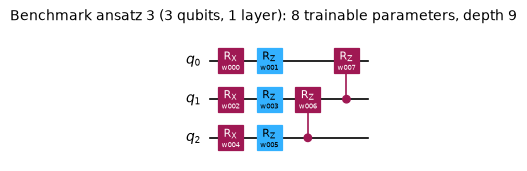

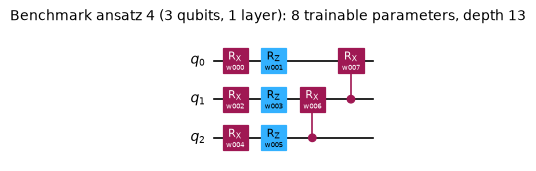

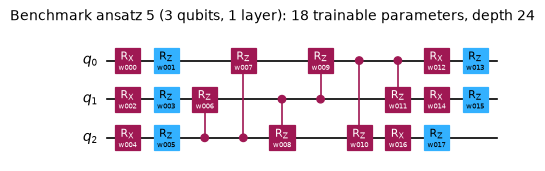

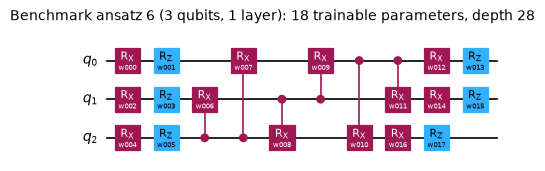

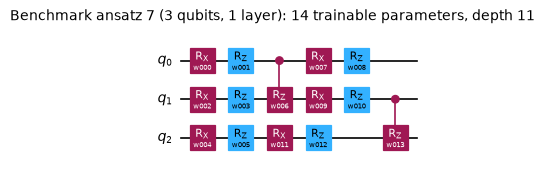

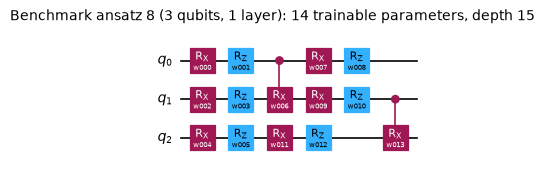

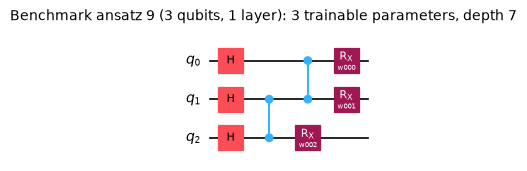

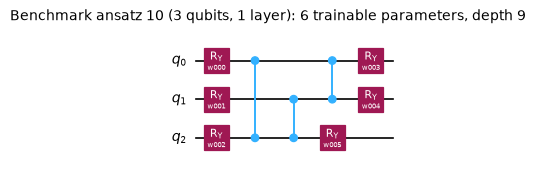

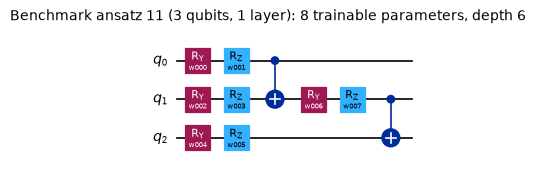

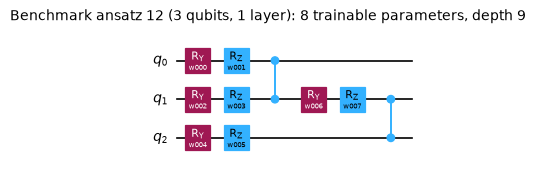

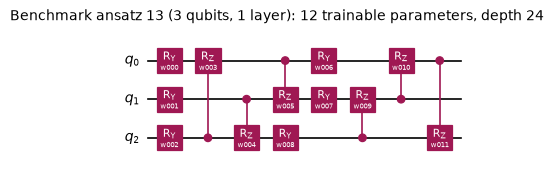

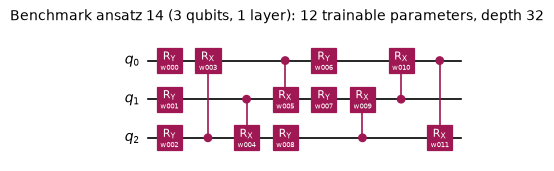

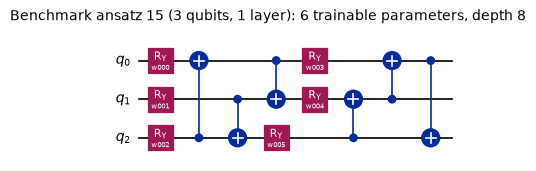

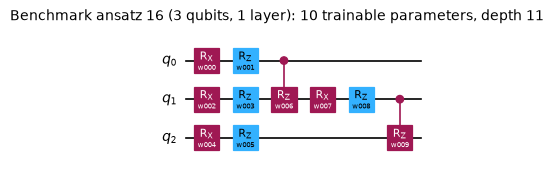

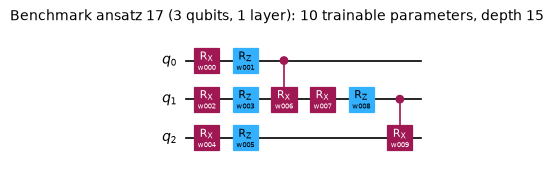

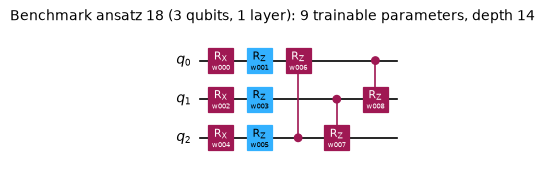

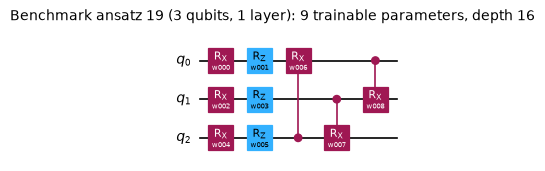

In [10]:
# ---- circuits of the ablation: Z feature map (7 qubits), amplitude encoding (3 qubits) and the 19 benchmark ansatzes ----
z7 = feature_map("Z", 7)
print(f"Z feature map: qubits=7, input angles=7, depth(decomposed)={deco(z7).depth()}, no entangling gates")
show_circuit(z7.decompose(), "Z feature map, 7 qubits, reps=2 (H, P)", fold=60, scale=0.45)

def ae_vectors(X):
    A = np.zeros((len(X), 8)); A[:, :7] = np.asarray(X, float)
    nrm = np.linalg.norm(A, axis=1, keepdims=True); A = np.where(nrm > 0, A / np.where(nrm > 0, nrm, 1), np.eye(8)[0])
    return A
def ae_circuit(amps):
    qc = QuantumCircuit(3, name="AE"); qc.append(StatePreparation(np.asarray(amps, complex)), [0, 1, 2]); return qc
amps = ae_vectors(X_tr[[3]])[0]
assert abs(abs(np.vdot(Statevector(ae_circuit(amps)).data, amps)) - 1) < 1e-9
print("Amplitude encoding: 7 raw features padded to 8 amplitudes -> 3 qubits; the state-preparation circuit really prepares the normalised amplitudes (asserted)")
show_circuit(ae_circuit(amps).decompose(), "Amplitude-encoding state preparation, 3 qubits (bound to training node 3)", fold=60, scale=0.6)

rows = [{"ansatz": k, "params (3 q, 1 layer)": len(sim_ansatz(k, 3)._plist), "params (7 q, 1 layer)": len(sim_ansatz(k, 7)._plist), "params (7 q, 2 layers)": len(sim_ansatz(k, 7, 2)._plist),
         "depth (3 q)": sim_ansatz(k, 3).decompose().depth(), "2-qubit gates (7 q)": sum(v for g, v in sim_ansatz(k, 7).count_ops().items() if g in ("cx", "cz", "crx", "crz"))} for k in range(1, 20)]
display(pd.DataFrame(rows).set_index("ansatz").T)
for k in range(1, 20):
    a = sim_ansatz(k, 3)
    show_circuit(a, f"Benchmark ansatz {k} (3 qubits, 1 layer): {len(a._plist)} trainable parameters, depth {a.decompose().depth()}", fold=-1, scale=0.6)

## 2. Exact simulation of these circuits, verified against Qiskit

* `GateSim` executes the gate list of a Qiskit circuit made of `h, rx, ry, rz, cx, cz, crx, crz` on a batch of state vectors (different parameter
  values per batch row are allowed, which is what the expressibility sampling needs).
  `GateSim.unitary(w)` equals `Operator(circuit.assign_parameters(w))` (asserted for the main ansatz with 7, 8 and 9 qubits and for all 19 benchmark
  ansatzes with 1 and 2 layers).
* The **feature-map states** are vectorised NumPy formulas: the ZZ map (`H^n`, then the diagonal phase
  `exp(i[sum_i 2 x_i b_i + sum_{i<j} 2 (pi - x_i)(pi - x_j)(b_i xor b_j)])`, repeated twice) and the Z map (a product state). They equal Qiskit's
  `Statevector` of the bound circuit (asserted for 7, 8 and 9 qubits).
* The **VQC** output is the parity probability `P(even) = (1 + <Z x ... x Z>)/2` of the circuit `ansatz . feature map |0>`, trained by COBYLA on the
  mean cross-entropy (base 2, probabilities clipped at 1e-10) exactly like Qiskit's `VQC`. The paper reads out the **parity of the whole bit string**;
  Qiskit's `VQC` class uses `x % 2`, i.e. only the last bit. Both read-outs are supported and both are asserted equal to Qiskit's training results
  (`SamplerQNN` with a parity `interpret` and the `VQC` class itself, same initial weights, same COBYLA budget).
* The **QSVM** kernel `|<phi(a)|phi(b)>|^2` is a matrix product of the exact states, fed to `SVC(kernel="precomputed", C=1)`; asserted equal to
  Qiskit's `FidelityStatevectorKernel` and `QSVC`.

In [11]:
class GateSim:
    """Exact state-vector simulator for circuits of h, rx, ry, rz, cx, cz, crx, crz (the gates used in this notebook).
    States are stored as columns (dim x batch) so that every gate is a contiguous vector operation. Consecutive single-qubit gates on one qubit
    are fused into one 2x2 matrix and consecutive CZ gates into one diagonal (pure speed-ups)."""
    NAMES = {"h", "rx", "ry", "rz", "cx", "cz", "crx", "crz"}
    ONE = {"h", "rx", "ry", "rz"}
    def __init__(self, qc, params):
        self.n = qc.num_qubits; self.dim = 2 ** self.n; self.P = len(params); self.ops = []
        pos = {p: i for i, p in enumerate(params)}
        ar = np.arange(self.dim); self.bit = [(ar >> k) & 1 for k in range(self.n)]
        for inst in qc.data:
            nm = inst.operation.name
            assert nm in self.NAMES, f"unsupported gate {nm}"
            q = [qc.find_bit(b).index for b in inst.qubits]
            idx = pos[inst.operation.params[0]] if inst.operation.params else None
            sign = 1.0 - 2.0 * (self.bit[q[0]] & self.bit[q[1]]) if nm == "cz" else None
            if nm == "cz" and self.ops and self.ops[-1][0] == "czg":          # merge consecutive CZ gates into one diagonal
                _, qs, sg = self.ops[-1]; self.ops[-1] = ("czg", qs + q, sg * sign)
            elif nm == "cz":
                self.ops.append(("czg", list(q), sign))
            else:
                self.ops.append((nm, q, idx))
        self._cx = {}
    @staticmethod
    def _mat(nm, th):
        """2x2 matrix of a single-qubit gate; th may be an array (one angle per batch column) -> shape (B, 2, 2)."""
        if nm == "h": return np.array([[1, 1], [1, -1]], complex) / np.sqrt(2)
        th = np.asarray(th, float); c, s = np.cos(th / 2), np.sin(th / 2); z = 0 * c
        if nm == "rx": g = (c + 0j, -1j * s, -1j * s, c + 0j)
        elif nm == "ry": g = (c + 0j, -s + 0j, s + 0j, c + 0j)
        else: g = (np.exp(-1j * th / 2), z + 0j, z + 0j, np.exp(1j * th / 2))
        return np.stack([np.stack([g[0], g[1]], -1), np.stack([g[2], g[3]], -1)], -2)
    def _apply1(self, x, M, k):
        B = x.shape[1]; v = x.reshape(self.dim >> (k + 1), 2, 1 << k, B); v0, v1 = v[:, 0], v[:, 1]
        g = [M[..., i, j] for i in (0, 1) for j in (0, 1)]                     # scalars, or arrays of shape (B,) broadcast along the batch axis
        out = np.empty_like(v)
        out[:, 0] = g[0] * v0 + g[1] * v1
        out[:, 1] = g[2] * v0 + g[3] * v1
        return out.reshape(self.dim, B)
    def _run_cols(self, x, W):
        W = np.asarray(W, float); pend = {}
        def flush(qs):
            nonlocal x
            for k in qs:
                if k in pend: x = self._apply1(x, pend.pop(k), k)
        for nm, q, idx in self.ops:
            if nm in self.ONE:
                M = self._mat(nm, None if idx is None else (W[idx] if W.ndim == 1 else W[:, idx]))
                pend[q[0]] = M if q[0] not in pend else np.matmul(M, pend[q[0]])
                continue
            flush(q)
            if nm == "czg": x = x * idx[:, None]                               # idx holds the merged diagonal sign vector
            elif nm == "cx":
                key = tuple(q)
                if key not in self._cx: self._cx[key] = np.arange(self.dim) ^ (self.bit[q[0]] << q[1])
                x = x[self._cx[key], :]
            else:                                                             # crx, crz: rotation of the target where the control bit is 1
                th = W[idx] if W.ndim == 1 else W[:, idx]
                p1 = self._apply1(x, self._mat(nm[1:], th), q[1])
                x = np.where(self.bit[q[0]][:, None] == 1, p1, x)
        flush(list(pend))
        return x
    def run(self, psi, W):
        """Apply the circuit to the rows of psi (B, 2^n). W: shared parameter vector (P,) or one vector per row (B, P)."""
        return self._run_cols(np.ascontiguousarray(psi.T), W).T
    def unitary(self, w):
        return self._run_cols(np.eye(self.dim, dtype=complex), w)

_SIMS = {}
def get_sim(key, build):
    if key not in _SIMS:
        a = build(); _SIMS[key] = (GateSim(a, plist(a)), a)
    return _SIMS[key][0]
def main_sim(n): return get_sim(("main", n), lambda: main_ansatz(n))
def abl_sim(k, n, layers): return get_sim(("abl", k, n, layers), lambda: sim_ansatz(k, n, layers))

def qiskit_unitary(ans, w):
    return Operator(ans.assign_parameters(dict(zip(plist(ans), w)))).data

# ---- unitaries: main ansatz (7, 8, 9 qubits) and the 19 benchmark ansatzes (1 and 2 layers, 3 and 7 qubits) ----
for n in (7, 8, 9):
    sim = main_sim(n); w = np.random.default_rng(n).uniform(0, 2 * np.pi, sim.P)
    assert np.allclose(sim.unitary(w), qiskit_unitary(main_ansatz(n), w), atol=1e-9), n
print("GateSim unitary == Operator of the TwoLocal ansatz for 7, 8 and 9 qubits")
t0 = time.time()
for k in range(1, 20):
    for n in (3, 7):
        for L in (1, 2):
            if n == 7 and L == 2 and k not in (1, 5, 9, 11, 16, 19): continue      # 7-qubit Operators are slow: a representative subset
            sim = abl_sim(k, n, L); w = np.random.default_rng(k + 10 * L).uniform(0, 2 * np.pi, sim.P)
            assert np.allclose(sim.unitary(w), qiskit_unitary(_SIMS[("abl", k, n, L)][1], w), atol=1e-9), (k, n, L)
print(f"GateSim unitary == Operator for all 19 benchmark ansatzes (3 qubits: 1 and 2 layers; 7 qubits: 1 layer, plus 2 layers for six of them)  [{time.time() - t0:.0f}s]")

GateSim unitary == Operator of the TwoLocal ansatz for 7, 8 and 9 qubits


GateSim unitary == Operator for all 19 benchmark ansatzes (3 qubits: 1 and 2 layers; 7 qubits: 1 layer, plus 2 layers for six of them)  [14s]


In [12]:
HN = {}
def hadamard_n(n):
    if n not in HN:
        H1 = np.array([[1, 1], [1, -1]]) / np.sqrt(2); M = np.array([[1.0]])
        for _ in range(n): M = np.kron(M, H1)
        HN[n] = M
    return HN[n]

def zz_states(A, reps=2, chunk=2000):
    """Exact states of zz_feature_map(n, reps, entanglement='full') for all rows of A (vectorised, chunked to bound memory)."""
    A = np.asarray(A, float); N, n = A.shape; dim = 2 ** n
    b = ((np.arange(dim)[:, None] >> np.arange(n)) & 1).astype(float)              # b[:, i] = value of qubit i
    pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
    xor = np.stack([np.abs(b[:, i] - b[:, j]) for i, j in pairs], axis=1)
    out = np.empty((N, dim), complex)
    for s in range(0, N, chunk):
        a = A[s:s + chunk]
        P = np.stack([(np.pi - a[:, i]) * (np.pi - a[:, j]) for i, j in pairs], axis=1)
        ph = np.exp(1j * (2 * a @ b.T + 2 * P @ xor.T)); psi = np.full((len(a), dim), 1 / np.sqrt(dim), complex) * ph
        for _ in range(reps - 1):
            psi = (psi @ hadamard_n(n)) * ph
        out[s:s + chunk] = psi
    return out

def z_states(A, reps=2):
    """Exact states of z_feature_map(n, reps) (H, P(2x) repeated): a product state."""
    A = np.asarray(A, float); N, n = A.shape; psi = np.ones((N, 1), complex)
    for i in reversed(range(n)):                                                   # qubit n-1 is the most significant bit
        ph = np.exp(2j * A[:, i]); s = np.stack([np.full(N, 1 / np.sqrt(2), complex), np.full(N, 1 / np.sqrt(2), complex) * ph], 1)
        for _ in range(reps - 1):
            s = np.stack([(s[:, 0] + s[:, 1]), (s[:, 0] - s[:, 1])], 1) / np.sqrt(2) * np.stack([np.ones(N), ph], 1)
        psi = (psi[:, :, None] * s[:, None, :]).reshape(N, -1)
    return psi

# ---- feature-map states vs Qiskit's Statevector (7, 8 and 9 qubits; the extra features are 0/1 labels as in the stacks) ----
rg = np.random.default_rng(1)
for n in (7, 8, 9):
    A = np.c_[X_tr[::53][:6], rg.integers(0, 2, (6, n - 7))] if n > 7 else X_tr[::53][:6]
    S = zz_states(A); fm = feature_map("ZZ", n)
    for a, s in zip(A, S):
        assert abs(abs(np.vdot(Statevector(fm.assign_parameters(a)).data, s)) - 1) < 1e-9, n
print("ZZ feature-map states == Qiskit Statevector (up to a global phase) for 7, 8 and 9 qubits")
A = X_tr[::37][:6]; S = z_states(A)
for a, s in zip(A, S): assert abs(abs(np.vdot(Statevector(feature_map("Z", 7).assign_parameters(a)).data, s)) - 1) < 1e-9
print("Z feature-map states == Qiskit Statevector for 7 qubits")

# ---- caches of the (unique-row) states, so that VQC and QSVM on the same inputs share them ----
_ZZ_CACHE = collections.OrderedDict()
def zz_cached(A):
    A = np.ascontiguousarray(np.asarray(A, float)); key = (A.shape, hashlib.md5(A.tobytes()).hexdigest())
    if key not in _ZZ_CACHE:
        Au, inv = np.unique(np.round(A, 12), axis=0, return_inverse=True)
        _ZZ_CACHE[key] = (zz_states(Au), inv.ravel())
        while len(_ZZ_CACHE) > 6: _ZZ_CACHE.popitem(last=False)
    return _ZZ_CACHE[key]
def kernel_block(Sa, ia, Sb, ib):
    return (np.abs(Sa @ Sb.conj().T) ** 2)[np.ix_(ia, ib)]

# ---- VQC read-out, loss and training ----
SIGNS = {}
def signs(n, readout="parity"):
    key = (n, readout)
    if key not in SIGNS:
        ar = np.arange(2 ** n)
        SIGNS[key] = (1 - 2 * np.array([bin(i).count("1") % 2 for i in ar])).astype(float) if readout == "parity" else (1 - 2 * (ar & 1)).astype(float)
    return SIGNS[key]
def p_phish(Phi, U, n, readout="parity"):
    """Probability of the 'phishing' outcome: even parity of the whole bit string (paper) or last bit = 0 (Qiskit VQC)."""
    return 0.5 * (1.0 + (np.abs(Phi @ U.T) ** 2) @ signs(n, readout))
def ce_loss(p, y):
    q = np.where(y == 1, p, 1 - p); return float(np.mean(-np.log2(np.clip(q, 1e-10, None))))

def fit_vqc_states(sim, Phi, y, w0, maxiter, readout="parity"):
    hist = []
    def loss(w):
        l = ce_loss(p_phish(Phi, sim.unitary(w), sim.n, readout), y); hist.append(l); return l
    res = COBYLA(maxiter=maxiter).minimize(loss, w0)
    return np.asarray(res.x), hist

# ---- equivalence with Qiskit: exact EstimatorQNN read-outs, Qiskit's CrossEntropyLoss, and the interpret function of Qiskit's VQC class ----
import inspect
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit.primitives import StatevectorEstimator
from qiskit_machine_learning.utils.loss_functions import CrossEntropyLoss
n = 7; sel_ = np.r_[0:15, 160:175]; Xs, ys = X_tr[sel_], y_tr[sel_]
fmq, ansq = feature_map("ZZ", n), n_local(n, ["ry", "rz"], "cz", entanglement="full", reps=2, parameter_prefix="w")
sim7 = main_sim(n); Phi_s = zz_states(Xs)
assert [str(p) for p in ansq.parameters] == [str(p) for p in plist(main_ansatz(n))], "weight order differs"
circ = QuantumCircuit(n); circ.compose(fmq, inplace=True); circ.compose(ansq, inplace=True)
OBS = {"parity": SparsePauliOp("Z" * n), "lsb": SparsePauliOp("I" * (n - 1) + "Z")}      # Qiskit is little-endian: the last character acts on qubit 0
for readout, obs in OBS.items():
    qnn = EstimatorQNN(circuit=circ, input_params=list(fmq.parameters), weight_params=list(ansq.parameters), observables=obs,
                       estimator=StatevectorEstimator(), input_gradients=False, default_precision=0.0)
    for trial in range(3):
        w = np.random.default_rng(10 + trial).random(sim7.P)
        p_q = 0.5 * (1 + qnn.forward(Xs, w)[:, 0]); p_m = p_phish(Phi_s, sim7.unitary(w), n, readout)
        l_q = float(CrossEntropyLoss().evaluate(np.c_[p_q, 1 - p_q], np.c_[ys, 1 - ys]).mean()); l_m = ce_loss(p_m, ys)
        assert np.abs(p_q - p_m).max() < 1e-9 and abs(l_q - l_m) < 1e-9, (readout, trial)
    print(f"read-out '{readout}': P(phishing) and the cross-entropy loss equal Qiskit's EstimatorQNN + CrossEntropyLoss (3 random weight vectors, tolerance 1e-9); loss example {l_m:.4f}")
print("\nInterpret function of Qiskit's own VQC class (this is why 'last-bit' is run as an extra row):")
print(inspect.getsource(VQC._get_interpret))

ZZ feature-map states == Qiskit Statevector (up to a global phase) for 7, 8 and 9 qubits


Z feature-map states == Qiskit Statevector for 7 qubits


read-out 'parity': P(phishing) and the cross-entropy loss equal Qiskit's EstimatorQNN + CrossEntropyLoss (3 random weight vectors, tolerance 1e-9); loss example 0.9945


read-out 'lsb': P(phishing) and the cross-entropy loss equal Qiskit's EstimatorQNN + CrossEntropyLoss (3 random weight vectors, tolerance 1e-9); loss example 1.0658

Interpret function of Qiskit's own VQC class (this is why 'last-bit' is run as an extra row):
    def _get_interpret(self, num_classes: int):
        def parity(x: int, num_classes: int = num_classes) -> int:
            return x % num_classes

        return parity



## 3. Evaluation helpers and the individual learners

All metrics treat **phishing as the positive class**. For every model we store the predictions on the test set and compute (i) metrics on the whole
test set (1:10 imbalanced: the setting of the paper's Figs. 5 to 7) and (ii) metrics averaged over `N_BAL_DRAWS` random balanced 150 + 150 subsets
(the setting that matches the scores of Table 2). Every learner has one interface, `fit_predict(name, X_train, y_train, [X_a, X_b, ...], seed)`, which
returns the hard labels for every array in the list; the same interface serves the base models (predict the training and the test data) and the meta
classifiers of the stacks (any number of features, hence any number of qubits).

In [13]:
RES = []          # one row per (model, seed)
PRED = {}         # predictions on the test set

def metric_row(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=[0, 1], zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return {"macro_f1": f1.mean(), "macro_prec": pr.mean(), "macro_rec": rc.mean(), "phish_f1": f1[1], "phish_prec": pr[1], "phish_rec": rc[1], "FN": fn, "FP": fp, "TP": tp, "TN": tn}

def register(model, kind, seed, pred, t_s, extra=None):
    pred = np.asarray(pred).astype(int)
    full = metric_row(y_te, pred)
    bal = pd.DataFrame([metric_row(y_te[i], pred[i]) for i in BAL_DRAWS]).mean()
    row = {"model": model, "kind": kind, "seed": seed, "t_s": t_s, **{f"full_{k}": v for k, v in full.items()}, **{f"bal_{k}": bal[k] for k in ("macro_f1", "phish_f1", "phish_prec", "phish_rec")}}
    if extra: row.update(extra)
    RES.append(row); PRED[(model, seed)] = pred
    return row

# ---------------- the learners ----------------
def sk_model(mk):
    def f(Xa, ya, Xl, seed):
        m = mk(seed).fit(Xa, ya); return [m.predict(X) for X in Xl]
    return f

def fp_qsvm(Xa, ya, Xl, seed):
    """QSVM-qiskit: SVC on the exact fidelity kernel of the ZZ feature map (raw features, n qubits for n features)."""
    S_a, i_a = zz_cached(Xa); K = kernel_block(S_a, i_a, S_a, i_a)
    svc = SVC(kernel="precomputed", C=1.0).fit(K, ya)
    out = []
    for X in Xl:
        S_b, i_b = zz_cached(X); out.append(svc.predict(kernel_block(S_b, i_b, S_a, i_a)))
    return out

def fp_vqc(Xa, ya, Xl, seed, readout="parity", maxiter=None):
    """VQC: ZZ feature map + TwoLocal(ry,rz;cz;reps=2), COBYLA, parity read-out; random initial weights in [0, 1) as in Qiskit."""
    n = Xa.shape[1]; sim = main_sim(n); S, inv = zz_cached(Xa); Phi = S[inv]
    w0 = np.random.default_rng(seed).random(sim.P)
    w, hist = fit_vqc_states(sim, Phi, ya, w0, VQC_MAXITER if maxiter is None else maxiter, readout)
    U = sim.unitary(w); out = []
    for X in Xl:
        S2, i2 = zz_cached(X); out.append((p_phish(S2, U, n, readout)[i2] > 0.5).astype(int))
    fp_vqc.last = {"w": w, "hist": hist}
    return out

def qsvm_qubo(K, y, precision=QA_PRECISION):
    ys = 2.0 * y - 1; N = len(y); p = np.asarray(precision, float); nb = len(p)
    P = np.kron(np.eye(N), p[None, :])                       # lambda = P @ b, shape (N, N*nb)
    Qm = K * np.outer(ys, ys)
    H = P.T @ Qm @ P; h = -P.T @ np.ones(N)                  # E(b) = 1/2 b^T H b + h^T b, b binary
    nv = N * nb
    iu, ju = np.triu_indices(nv, 1)
    bqm = dimod.BinaryQuadraticModel.from_numpy_vectors(0.5 * np.diag(H) + h, (iu, ju, H[iu, ju]), 0.0, "BINARY")     # same QUBO as a dict-built model, built faster
    return bqm, P, H, h

def fp_anneal(Xa, ya, Xl, seed):
    """QSVM-dwave: SVM dual with an RBF kernel (sigma = 150) as a QUBO with precision vector [1, 2]; simulated annealing instead of D-Wave."""
    gamma = 1.0 / (2.0 * SIGMA ** 2); K = rbf_kernel(Xa, Xa, gamma=gamma)
    bqm, P, H, h = qsvm_qubo(K, ya)
    ss = SimulatedAnnealingSampler().sample(bqm, num_reads=QA_READS, num_sweeps=QA_SWEEPS, seed=int(seed))
    best = ss.first; bvec = np.array([best.sample[i] for i in range(len(bqm.variables))], float)
    lam = P @ bvec; ys = 2.0 * ya - 1
    b_off = float(np.mean(ys - (lam * ys) @ K))
    fp_anneal.last = {"energy": float(best.energy), "n_sv": int((lam > 0).sum()), "check": abs(best.energy - (0.5 * bvec @ H @ bvec + h @ bvec))}
    return [((rbf_kernel(X, Xa, gamma=gamma) @ (lam * ys) + b_off) > 0).astype(int) for X in Xl]

FIT_PREDICT = {
    "LGBM":    sk_model(lambda s: LGBM(s)),
    "SVM-rbf": sk_model(lambda s: SVC(kernel="rbf")),
    "RF":      sk_model(lambda s: RandomForestClassifier(n_estimators=100, random_state=s, n_jobs=1)),
    "LR":      sk_model(lambda s: LogisticRegression(max_iter=1000)),          # CHOICE: max_iter raised from the default 100 so that it converges on raw features
    "QSVM":    fp_qsvm,
    "VQC":     fp_vqc,
    "QSVM-anneal": fp_anneal,
}
def fit_predict(name, Xa, ya, Xl, seed):
    return FIT_PREDICT[name](Xa, ya, Xl, seed)

In [14]:
# ---- equivalence: QSVM against Qiskit's QSVC + FidelityStatevectorKernel (7 and 8 qubits), and the QUBO against its definition ----
Xk = X_tr[np.r_[0:25, 160:185]]; yk = y_tr[np.r_[0:25, 160:185]]
fmk = feature_map("ZZ", 7)
S_k, i_k = zz_cached(Xk); K_mine = kernel_block(S_k, i_k, S_k, i_k)
assert np.allclose(K_mine, FidelityStatevectorKernel(feature_map=fmk).evaluate(Xk), atol=1e-9), "hand-made kernel differs from FidelityStatevectorKernel"
qsvc = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=fmk)).fit(Xk, yk)
Xq = X_te[:120]
assert (qsvc.predict(Xq) == fp_qsvm(Xk, yk, [Xq], 0)[0]).all(), "QSVC predictions differ"
print("QSVM, 7 qubits: hand-made kernel == FidelityStatevectorKernel (50 x 50); QSVC predictions == SVC(precomputed) on 120 test nodes")
X8 = np.c_[Xk, yk]; Xq8 = np.c_[Xq, (np.arange(120) % 2)]
fm8 = feature_map("ZZ", 8)
assert np.allclose(kernel_block(*zz_cached(X8), *zz_cached(X8)), FidelityStatevectorKernel(feature_map=fm8).evaluate(X8), atol=1e-9)
assert (QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=fm8)).fit(X8, yk).predict(Xq8) == fp_qsvm(X8, yk, [Xq8], 0)[0]).all()
print("QSVM, 8 qubits (one appended label feature, as in a stack): kernel and QSVC predictions equal Qiskit's as well")
_ = fp_anneal(Xk, yk, [Xq], 0); assert fp_anneal.last["check"] < 1e-6
print(f"QUBO: energy of the best sample equals 1/2 b^T H b + h^T b (difference {fp_anneal.last['check']:.1e}); {len(Xk) * len(QA_PRECISION)} binary variables for the check subset")

QSVM, 7 qubits: hand-made kernel == FidelityStatevectorKernel (50 x 50); QSVC predictions == SVC(precomputed) on 120 test nodes


QSVM, 8 qubits (one appended label feature, as in a stack): kernel and QSVC predictions equal Qiskit's as well


QUBO: energy of the best sample equals 1/2 b^T H b + h^T b (difference 5.7e-14); 100 binary variables for the check subset


In [15]:
# ---- individual learners on the 320 training nodes (160 + 160), evaluated on the test set ----
IND = ["SVM-rbf", "LGBM", "RF", "QSVM", "VQC", "QSVM-anneal"]
BASEP = {}                                      # (model, seed) -> (labels on the training nodes, labels on the test nodes)
for s in range(N_SEEDS):
    seed = SEED + s
    for name in IND:
        t0 = time.time(); p_tr, p_te = fit_predict(name, X_tr, y_tr, [X_tr, X_te], seed); dt = time.time() - t0
        BASEP[(name, s)] = (p_tr, p_te)
        register(name, "single", s, p_te, dt)
        if name == "VQC": VQC_HIST = fp_vqc.last["hist"]
        print(f"seed {s}  {name:12s} {dt:6.1f}s  macro-F1 full {RES[-1]['full_macro_f1']:.3f}  balanced {RES[-1]['bal_macro_f1']:.3f}  FP {RES[-1]['full_FP']:.0f}  FN {RES[-1]['full_FN']:.0f}", flush=True)
    # extra: Qiskit's own VQC measures only the last bit (x % 2) instead of the parity of the whole bit string
    t0 = time.time(); p_tr, p_te = fp_vqc(X_tr, y_tr, [X_tr, X_te], seed, readout="lsb"); dt = time.time() - t0
    register("VQC (last-bit read-out)", "single-extra", s, p_te, dt)
COLS = ["full_macro_f1", "full_phish_f1", "full_phish_prec", "full_phish_rec", "full_FP", "full_FN", "bal_macro_f1", "bal_phish_f1", "bal_phish_rec", "t_s"]
def show(kind=None, models=None, cols=COLS):
    df = pd.DataFrame(RES)
    if kind is not None: df = df[df["kind"] == kind]
    if models is not None: df = df[df["model"].isin(models)]
    g = df.groupby("model", sort=False)[list(cols)].mean()
    if df["seed"].nunique() > 1: g = g.join(df.groupby("model", sort=False)[["full_macro_f1", "bal_macro_f1"]].std().add_suffix("_std"))
    return g.round(3)
display(show("single")); display(show("single-extra"))

seed 0  SVM-rbf         4.1s  macro-F1 full 0.728  balanced 0.686  FP 324  FN 559


seed 0  LGBM            2.1s  macro-F1 full 0.821  balanced 0.945  FP 849  FN 32


seed 0  RF              5.0s  macro-F1 full 0.793  balanced 0.936  FP 1048  FN 31


seed 0  QSVM            3.2s  macro-F1 full 0.657  balanced 0.872  FP 2377  FN 19


seed 0  VQC            14.0s  macro-F1 full 0.527  balanced 0.600  FP 2715  FN 506


...

seed 4  QSVM            2.2s  macro-F1 full 0.657  balanced 0.872  FP 2377  FN 19


seed 4  VQC            19.6s  macro-F1 full 0.549  balanced 0.619  FP 2339  FN 514


seed 4  QSVM-anneal    27.6s  macro-F1 full 0.758  balanced 0.762  FP 459  FN 431


,full_macro_f1,full_phish_f1,full_phish_prec,full_phish_rec,full_FP,full_FN,bal_macro_f1,bal_phish_f1,bal_phish_rec,t_s,full_macro_f1_std,bal_macro_f1_std
model,,,,,,,,,,,,
SVM-rbf,0.728,0.500,0.576,0.441,324.0,559.0,0.686,0.604,0.448,3.904,0.000,0.000
LGBM,0.821,0.687,0.533,0.968,849.0,32.0,0.945,0.946,0.968,1.655,0.000,0.000
RF,0.805,0.661,0.503,0.965,953.2,35.4,0.937,0.939,0.965,5.082,0.007,0.001
QSVM,0.657,0.450,0.292,0.981,2377.0,19.0,0.872,0.886,0.981,2.123,0.000,0.000
VQC,0.556,0.264,0.180,0.496,2275.8,503.6,0.624,0.571,0.491,17.295,0.020,0.016
QSVM-anneal,0.758,0.561,0.555,0.567,454.6,433.4,0.761,0.718,0.589,27.467,0.002,0.002


,full_macro_f1,full_phish_f1,full_phish_prec,full_phish_rec,full_FP,full_FN,bal_macro_f1,bal_phish_f1,bal_phish_rec,t_s,full_macro_f1_std,bal_macro_f1_std
model,,,,,,,,,,,,
VQC (last-bit read-out),0.54,0.253,0.168,0.516,2598.2,483.8,0.621,0.576,0.509,19.48,0.023,0.02


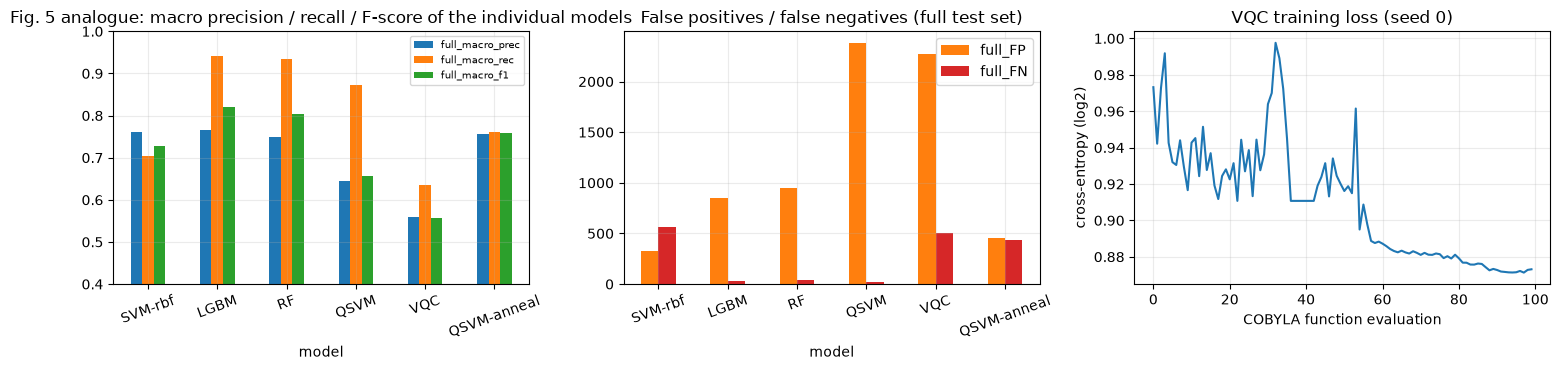

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
d = pd.DataFrame(RES); d = d[d["kind"] == "single"].groupby("model", sort=False)[["full_macro_prec", "full_macro_rec", "full_macro_f1", "full_FP", "full_FN"]].mean()
d[["full_macro_prec", "full_macro_rec", "full_macro_f1"]].plot.bar(ax=ax[0], rot=20); ax[0].set_ylim(0.4, 1); ax[0].set_title("Fig. 5 analogue: macro precision / recall / F-score of the individual models"); ax[0].legend(fontsize=7)
d[["full_FP", "full_FN"]].plot.bar(ax=ax[1], rot=20, color=["tab:orange", "tab:red"]); ax[1].set_title("False positives / false negatives (full test set)")
ax[2].plot(VQC_HIST); ax[2].set_xlabel("COBYLA function evaluation"); ax[2].set_ylabel("cross-entropy (log2)"); ax[2].set_title("VQC training loss (seed 0)")
plt.tight_layout(); plt.show()

## 4. Classical ensembles: stacking

**Two-level stacking (Fig. 2 of the paper).** Every base model is trained on the 320 training nodes; it then labels the *training* nodes and the *test*
nodes; these labels are appended as extra features to the original 7 (so 8 features for one base model, 9 for two); the meta classifier is trained on
the augmented training data and evaluated on the augmented test data. This is exactly what the authors' notebooks do, including the fact that the base
models label their own training data (in-sample), which makes their labels look more reliable to the meta classifier than they are on new data.
We run **every** combination of one or two base models from {LGBM, SVM, QSVM, VQC, QSVM-dwave} and a meta classifier from {LR, LGBM, SVM, QSVM,
QSVM-dwave} that is not one of its own bases, and a VQC meta classifier for a few stacks (`VQC_META_STACKS`): a quantum meta classifier simply gets 8 or 9 qubits
(one per feature, Section 2), and training it is by far the most expensive step on a CPU. As an extra the
*out-of-fold* variant replaces the in-sample base labels on the training data by 5-fold cross-validated labels (the textbook way to avoid that
optimism); the test labels come from the base model fitted on all 320 training nodes in both variants.

The paper reports the **best** ensembles (Fig. 6: top 10 by macro F-score). Picking the best of many ensembles on the test set is optimistic by
construction, so the tables below show the whole distribution and the top 10 side by side.

In [17]:
OOFP = {}
def oof_labels(name, s):
    """5-fold out-of-fold labels of a base model on the training nodes."""
    if (name, s) not in OOFP:
        seed = SEED + s; oof = np.zeros(len(y_tr), int)
        for a, b in StratifiedKFold(5, shuffle=True, random_state=seed).split(X_tr, y_tr):
            oof[b] = fit_predict(name, X_tr[a], y_tr[a], [X_tr[b]], seed)[0]
        OOFP[(name, s)] = oof
    return OOFP[(name, s)]

def run_stack(bases, meta, s, oof=False):
    seed = SEED + s
    p_tr = [oof_labels(b, s) if oof else BASEP[(b, s)][0] for b in bases]; p_te = [BASEP[(b, s)][1] for b in bases]
    Xa, Xb = np.c_[X_tr, np.array(p_tr).T], np.c_[X_te, np.array(p_te).T]          # labels appended as extra features
    t0 = time.time(); pred = fit_predict(meta, Xa, y_tr, [Xb], seed + 1000)[0]; dt = time.time() - t0
    name = ("+".join(bases)) + " -> " + meta + (" [OOF]" if oof else "")
    return register(name, "stack-oof" if oof else "stack", s, pred, dt, {"bases": "+".join(bases), "meta": meta, "n_bases": len(bases)})

COMBOS = [(b, m) for k in range(1, STACK_MAX_BASES + 1) for b in itertools.combinations(BASE_POOL, k) for m in META_POOL if m not in b]
COMBOS += [(b, "VQC") for b in VQC_META_STACKS]                         # 8- and 9-qubit VQC as meta classifier (a few stacks only)
print(len(COMBOS), "ensembles per run" + (" (+ the same with out-of-fold base labels for the first run)" if OOF_STACKS else ""), "| runs:", min(N_SEEDS, N_AUX_SEEDS))
t_all = time.time()
for s in range(min(N_SEEDS, N_AUX_SEEDS)):
    for ci, (b, m) in enumerate(COMBOS):
        if m == "VQC" and s > 0: continue                               # the slow 8- and 9-qubit VQC meta classifiers: first run only
        run_stack(b, m, s)
        if ci % 10 == 9: print(f"seed {s}: {ci + 1}/{len(COMBOS)} stacks  ({time.time() - t_all:.0f}s)", flush=True)
    if OOF_STACKS and s == 0:
        for ci, (b, m) in enumerate(COMBOS):
            if m == "VQC": continue
            run_stack(b, m, s, oof=True)
            if ci % 10 == 9: print(f"seed {s}: OOF {ci + 1}/{len(COMBOS)} stacks  ({time.time() - t_all:.0f}s)", flush=True)
print(f"stacking done in {time.time() - t_all:.0f}s")

57 ensembles per run (+ the same with out-of-fold base labels for the first run) | runs: 2


seed 0: 10/57 stacks  (114s)


seed 0: 20/57 stacks  (227s)


seed 0: 30/57 stacks  (354s)


seed 0: 40/57 stacks  (466s)


...

seed 1: 20/57 stacks  (1921s)


seed 1: 30/57 stacks  (2001s)


seed 1: 40/57 stacks  (2084s)


seed 1: 50/57 stacks  (2156s)


stacking done in 2192s


In [18]:
D = pd.DataFrame(RES)
ST = D[D["kind"] == "stack"].groupby("model", sort=False).agg(bases=("bases", "first"), meta=("meta", "first"), n_bases=("n_bases", "first"),
        full_macro_f1=("full_macro_f1", "mean"), full_macro_f1_std=("full_macro_f1", "std"), full_phish_f1=("full_phish_f1", "mean"), full_macro_prec=("full_macro_prec", "mean"),
        full_macro_rec=("full_macro_rec", "mean"), full_FP=("full_FP", "mean"), full_FN=("full_FN", "mean"), full_TN=("full_TN", "mean"),
        bal_macro_f1=("bal_macro_f1", "mean"), bal_phish_f1=("bal_phish_f1", "mean"), t_s=("t_s", "mean")).sort_values("full_macro_f1", ascending=False)
ST["has_quantum"] = ST["bases"].str.contains("QSVM|VQC") | ST["meta"].str.contains("QSVM|VQC")
ST["has_qsvm_qiskit"] = ST["bases"].str.split("+").apply(lambda l: "QSVM" in l) | (ST["meta"] == "QSVM")
ST["has_anneal"] = ST["bases"].str.contains("QSVM-anneal") | (ST["meta"] == "QSVM-anneal")
print("Top 10 ensembles by macro F-score on the full test set (as in the paper's Fig. 6; chosen on the test set, hence optimistic):")
display(ST.head(10)[["full_macro_f1", "full_macro_f1_std", "full_macro_prec", "full_macro_rec", "full_phish_f1", "full_FP", "full_FN", "bal_macro_f1", "has_quantum"]].round(3))
single = D[D["kind"] == "single"].groupby("model", sort=False)[["full_macro_f1", "full_phish_f1", "full_FP", "full_FN", "bal_macro_f1", "bal_phish_f1"]].mean()
print(f"All {len(ST)} ensembles: macro-F1 median {ST['full_macro_f1'].median():.3f}, best {ST['full_macro_f1'].max():.3f}, worst {ST['full_macro_f1'].min():.3f}; "
      f"individual models: best {single['full_macro_f1'].max():.3f} ({single['full_macro_f1'].idxmax()}), median {single['full_macro_f1'].median():.3f}")
if OOF_STACKS:
    SO = D[D["kind"] == "stack-oof"].groupby("model", sort=False)[["full_macro_f1", "full_phish_f1", "full_FP", "full_FN"]].mean().sort_values("full_macro_f1", ascending=False)
    print(f"Out-of-fold variant: median macro-F1 {SO['full_macro_f1'].median():.3f}, best {SO['full_macro_f1'].max():.3f} ({SO['full_macro_f1'].idxmax()})")

Top 10 ensembles by macro F-score on the full test set (as in the paper's Fig. 6; chosen on the test set, hence optimistic):


,full_macro_f1,full_macro_f1_std,full_macro_prec,full_macro_rec,full_phish_f1,full_FP,full_FN,bal_macro_f1,has_quantum
model,,,,,,,,,
SVM-rbf -> LGBM,0.821,0.000,0.765,0.942,0.687,849.0,32.0,0.945,False
LGBM+VQC -> LR,0.819,0.000,0.763,0.940,0.684,859.0,34.0,0.944,True
LGBM+SVM-rbf -> LR,0.819,0.000,0.763,0.940,0.684,861.0,33.0,0.944,False
LGBM+QSVM-anneal -> LR,0.818,0.000,0.763,0.940,0.684,862.0,33.0,0.944,True
LGBM -> LR,0.818,0.000,0.763,0.940,0.684,862.0,33.0,0.944,False
SVM-rbf+QSVM-anneal -> LGBM,0.816,0.000,0.760,0.940,0.680,883.0,31.0,0.942,True
SVM-rbf+VQC -> LGBM,0.815,0.009,0.759,0.939,0.678,886.0,33.0,0.940,True
VQC -> LGBM,0.815,0.009,0.759,0.939,0.678,886.0,33.0,0.940,True
VQC+QSVM-anneal -> LGBM,0.814,0.007,0.758,0.939,0.676,893.5,33.5,0.941,True


All 57 ensembles: macro-F1 median 0.728, best 0.821, worst 0.579; individual models: best 0.821 (LGBM), median 0.743
Out-of-fold variant: median macro-F1 0.761, best 0.823 (LGBM+QSVM -> LR [OOF])


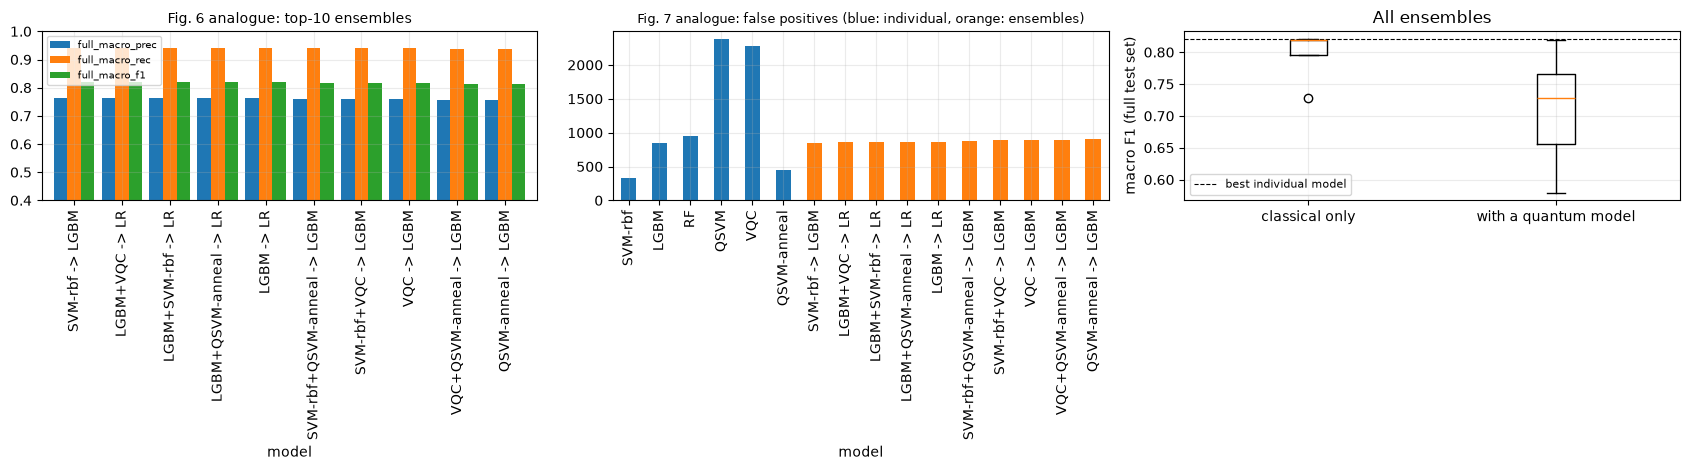

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
top = ST.head(10)
top[["full_macro_prec", "full_macro_rec", "full_macro_f1"]].plot.bar(ax=ax[0], rot=90, width=0.85); ax[0].set_ylim(0.4, 1); ax[0].set_title("Fig. 6 analogue: top-10 ensembles", fontsize=10); ax[0].legend(fontsize=7)
fpdf = pd.concat([single["full_FP"].rename("FP").to_frame().assign(group="individual"), top["full_FP"].rename("FP").to_frame().assign(group="top-10 ensemble")])
fpdf["FP"].plot.bar(ax=ax[1], rot=90, color=["tab:blue"] * len(single) + ["tab:orange"] * len(top)); ax[1].set_title("Fig. 7 analogue: false positives (blue: individual, orange: ensembles)", fontsize=9)
ax[2].boxplot([ST.loc[~ST["has_quantum"], "full_macro_f1"].values, ST.loc[ST["has_quantum"], "full_macro_f1"].values]); ax[2].set_xticklabels(["classical only", "with a quantum model"])
ax[2].axhline(single["full_macro_f1"].max(), color="k", ls="--", lw=0.8, label="best individual model"); ax[2].set_ylabel("macro F1 (full test set)"); ax[2].set_title("All ensembles"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Voting, for reference

Plain majority voting over the individual models' labels (no meta classifier). It is not in the paper (which uses stacking and bagging); it shows how much
of the gain comes from simply combining the labels.

In [20]:
VOTES = {"vote: 3 quantum models (QSVM, VQC, QSVM-dwave)": ["QSVM", "VQC", "QSVM-anneal"], "vote: LGBM + QSVM + VQC": ["LGBM", "QSVM", "VQC"],
         "vote: all 5 base models": BASE_POOL, "vote: 3 classical models (SVM, LGBM, RF)": ["SVM-rbf", "LGBM", "RF"]}
for name, members in VOTES.items():
    for s in range(N_SEEDS):
        pred = (np.mean([BASEP[(m, s)][1] for m in members], axis=0) > 0.5).astype(int)
        register(name, "vote", s, pred, 0.0)
display(show("vote"))

,full_macro_f1,full_phish_f1,full_phish_prec,full_phish_rec,full_FP,full_FN,bal_macro_f1,bal_phish_f1,bal_phish_rec,t_s,full_macro_f1_std,bal_macro_f1_std
model,,,,,,,,,,,,
"vote: 3 quantum models (QSVM, VQC, QSVM-dwave)",0.710,0.501,0.372,0.770,1302.4,229.6,0.821,0.813,0.777,0.0,0.004,0.005
vote: LGBM + QSVM + VQC,0.736,0.557,0.390,0.973,1522.4,27.2,0.911,0.917,0.973,0.0,0.004,0.003
vote: all 5 base models,0.807,0.656,0.563,0.786,609.4,214.2,0.864,0.854,0.792,0.0,0.004,0.007
"vote: 3 classical models (SVM, LGBM, RF)",0.832,0.706,0.557,0.963,767.2,36.8,0.947,0.948,0.964,0.0,0.002,0.000


## 5. Three-level stacking

The paper stacks **GCN** (level 0), **QSVM-qiskit and LGBM** (level 1) and a **logistic regression** (meta). The GCN needs the 3-million-node graph and
cannot be run, so a classical node-feature model stands in for it (`# CHOICE`): first the RBF-SVM, then LGBM. The mechanics are the paper's: the level-0 label
is appended to the features; level-1 models are trained on those 8 features and their labels are appended again (10 features); the logistic regression is
trained on the result.

In [21]:
def three_level(l0, s):
    seed = SEED + s; p0_tr, p0_te = BASEP[(l0, s)]
    XA, XB = np.c_[X_tr, p0_tr], np.c_[X_te, p0_te]
    t0 = time.time()
    q_tr, q_te = fit_predict("QSVM", XA, y_tr, [XA, XB], seed); g_tr, g_te = fit_predict("LGBM", XA, y_tr, [XA, XB], seed)
    XA2, XB2 = np.c_[XA, q_tr, g_tr], np.c_[XB, q_te, g_te]
    pred = fit_predict("LR", XA2, y_tr, [XB2], seed)[0]
    return register(f"3-level: {l0} (stand-in for GCN) -> QSVM + LGBM -> LR", "stack3", s, pred, time.time() - t0)
for l0 in ("SVM-rbf", "LGBM"):
    for s in range(min(N_SEEDS, N_AUX_SEEDS)): three_level(l0, s)
display(show("stack3"))

,full_macro_f1,full_phish_f1,full_phish_prec,full_phish_rec,full_FP,full_FN,bal_macro_f1,bal_phish_f1,bal_phish_rec,t_s,full_macro_f1_std,bal_macro_f1_std
model,,,,,,,,,,,,
3-level: SVM-rbf (stand-in for GCN) -> QSVM + LGBM -> LR,0.810,0.670,0.513,0.967,918.0,33.0,0.941,0.943,0.968,6.591,0.0,0.0
3-level: LGBM (stand-in for GCN) -> QSVM + LGBM -> LR,0.815,0.679,0.523,0.967,883.0,33.0,0.943,0.944,0.968,6.482,0.0,0.0


## 6. Bagging

Five models of the same type are trained, each on the 160 phishing nodes and a **different random set of 160 non-phishing nodes** (drawn from the 800
non-phishing nodes of the training file); all five label the same test set. Their labels are combined by **maximum voting** (at least 3 of 5 say phishing)
or by a **weighted average** with the phishing F1 of each model as weight. The paper does not say on which data the weights are computed; the weights
here come from each model's phishing F1 on the 960 training-file nodes (no test information, `# CHOICE`); the variant with the weights taken from the test
set, which seems to be what the paper did, is shown as `[paper-literal]`.

In [22]:
from sklearn.metrics import f1_score
def bagging(model, s):
    seed = SEED + s; r = np.random.default_rng(seed); nonph = np.flatnonzero(yfile_tr == 0); P_te, W_tr, W_te = [], [], []
    t0 = time.time()
    for b in range(N_BAGS):
        idx = np.r_[np.arange(160), r.choice(nonph, 160, replace=False)]
        p_te, p_file = fit_predict(model, Xfile_tr[idx], yfile_tr[idx], [X_te, Xfile_tr], seed + b)
        P_te.append(p_te); W_tr.append(f1_score(yfile_tr, p_file, pos_label=1)); W_te.append(f1_score(y_te, p_te, pos_label=1))
        register(f"bag member: {model}", "bag-member", s * 10 + b, p_te, 0.0)
    P_te = np.array(P_te); dt = time.time() - t0
    register(f"bagging {model}: max voting", "bag", s, (P_te.sum(0) >= (N_BAGS // 2 + 1)).astype(int), dt)
    register(f"bagging {model}: F1-weighted", "bag", s, ((np.array(W_tr)[:, None] * P_te).sum(0) / np.sum(W_tr) > 0.5).astype(int), dt)
    register(f"bagging {model}: F1-weighted [paper-literal]", "bag", s, ((np.array(W_te)[:, None] * P_te).sum(0) / np.sum(W_te) > 0.5).astype(int), dt)
for model in ("QSVM", "VQC", "QSVM-anneal"):
    for s in range(min(N_SEEDS, N_AUX_SEEDS)): bagging(model, s)
    print(model, "bagging done", flush=True)
bag_members = pd.DataFrame(RES); bag_members = bag_members[bag_members["kind"] == "bag-member"].groupby("model", sort=False)[COLS[:-1]].mean().round(3)
print("Mean of the five bag members (the 'individual runs'):"); display(bag_members)
print("Bagged ensembles:"); display(show("bag"))

QSVM bagging done


VQC bagging done


QSVM-anneal bagging done


Mean of the five bag members (the 'individual runs'):


,full_macro_f1,full_phish_f1,full_phish_prec,full_phish_rec,full_FP,full_FN,bal_macro_f1,bal_phish_f1,bal_phish_rec
model,,,,,,,,,
bag member: QSVM,0.655,0.447,0.290,0.974,2391.1,26.1,0.867,0.881,0.973
bag member: VQC,0.565,0.274,0.190,0.498,2148.5,502.0,0.630,0.576,0.493
bag member: QSVM-anneal,0.758,0.561,0.551,0.572,467.2,427.5,0.762,0.720,0.593


Bagged ensembles:


,full_macro_f1,full_phish_f1,full_phish_prec,full_phish_rec,full_FP,full_FN,bal_macro_f1,bal_phish_f1,bal_phish_rec,t_s,full_macro_f1_std,bal_macro_f1_std
model,,,,,,,,,,,,
bagging QSVM: max voting,0.659,0.452,0.294,0.980,2350.0,20.5,0.873,0.887,0.980,17.700,0.002,0.001
bagging QSVM: F1-weighted,0.659,0.452,0.294,0.980,2350.0,20.5,0.873,0.887,0.980,17.700,0.002,0.001
bagging QSVM: F1-weighted [paper-literal],0.659,0.452,0.294,0.980,2350.0,20.5,0.873,0.887,0.980,17.700,0.002,0.001
bagging VQC: max voting,0.591,0.306,0.219,0.509,1818.0,491.0,0.651,0.595,0.501,103.533,0.003,0.008
bagging VQC: F1-weighted,0.591,0.306,0.219,0.509,1818.0,491.0,0.651,0.595,0.501,103.533,0.003,0.008
bagging VQC: F1-weighted [paper-literal],0.591,0.306,0.219,0.509,1818.0,491.0,0.651,0.595,0.501,103.533,0.003,0.008
bagging QSVM-anneal: max voting,0.757,0.559,0.554,0.564,453.5,436.0,0.759,0.714,0.585,111.950,0.003,0.004
bagging QSVM-anneal: F1-weighted,0.757,0.559,0.554,0.564,453.5,436.0,0.759,0.714,0.585,111.950,0.003,0.004
bagging QSVM-anneal: F1-weighted [paper-literal],0.757,0.559,0.554,0.564,453.5,436.0,0.759,0.714,0.585,111.950,0.003,0.004


## 7. Training time against training-set size (Figure 4)

The paper times QSVM-qiskit and VQC for training sets from a few hundred up to 20,000 nodes on the IBM state-vector simulator (QSVM 1,389 s for 20 K nodes,
VQC 56,903 s). The authors' file holds only 960 training nodes, so the sizes here stop at 960 and the timings are those of **this notebook's exact simulator**
(and, for the QSVM, of Qiskit's `QSVC` + `FidelityStatevectorKernel` for sizes up to `QISKIT_MAX`): the absolute numbers are not comparable with the
paper's, only the *shape* of the growth is. Training sets with `n` nodes contain `min(n/2, 160)` phishing nodes and the rest non-phishing nodes.

{'n_train': 40, 'QSVM (this notebook) s': 0.022464752197265625, 'QSVC (Qiskit) s': 3.675147294998169, 'VQC (this notebook) s': 7.072529315948486}


{'n_train': 80, 'QSVM (this notebook) s': 0.11416220664978027, 'QSVC (Qiskit) s': 5.180238246917725, 'VQC (this notebook) s': 6.839749097824097}


{'n_train': 160, 'QSVM (this notebook) s': 0.137894868850708, 'QSVC (Qiskit) s': 15.77876591682434, 'VQC (this notebook) s': 13.69534420967102}


{'n_train': 320, 'QSVM (this notebook) s': 0.3991127014160156, 'QSVC (Qiskit) s': 42.049376487731934, 'VQC (this notebook) s': 21.589403867721558}


{'n_train': 640, 'QSVM (this notebook) s': 0.759990930557251, 'VQC (this notebook) s': 23.36254096031189}


{'n_train': 960, 'QSVM (this notebook) s': 0.8984279632568359, 'VQC (this notebook) s': 16.954001426696777}


,QSVM (this notebook) s,QSVC (Qiskit) s,VQC (this notebook) s
n_train,,,
40,0.022,3.675,7.073
80,0.114,5.180,6.840
160,0.138,15.779,13.695
320,0.399,42.049,21.589
640,0.760,NaN,23.363
960,0.898,NaN,16.954


log-log slope of training time against training size: {'QSVM (this notebook) s': np.float64(1.11), 'QSVC (Qiskit) s': np.float64(1.22), 'VQC (this notebook) s': np.float64(0.39)}


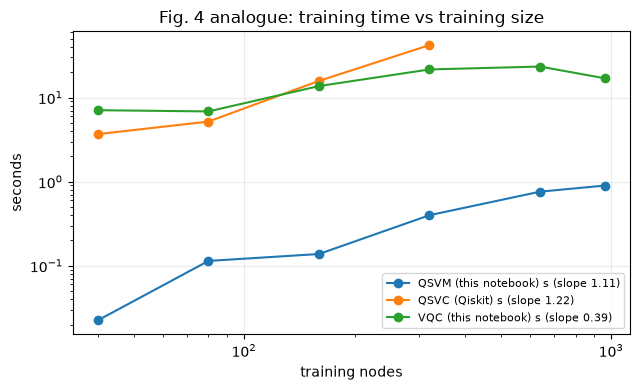

In [23]:
QISKIT_MAX = 160 if FAST_MODE else 320
def scale_set(n):
    ph = min(n // 2, 160); idx = np.r_[np.arange(ph), 160 + np.arange(n - ph)]; return Xfile_tr[idx], yfile_tr[idx]
TIMES = []
for n in SCALE_SIZES:
    Xs_, ys_ = scale_set(n); row = {"n_train": n}
    t0 = time.time(); S = zz_states(Xs_); K = (np.abs(S @ S.conj().T) ** 2); SVC(kernel="precomputed", C=1.0).fit(K, ys_); row["QSVM (this notebook) s"] = time.time() - t0
    if n <= QISKIT_MAX:
        t0 = time.time(); QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=feature_map("ZZ", 7))).fit(Xs_, ys_); row["QSVC (Qiskit) s"] = time.time() - t0
    sim = main_sim(7); t0 = time.time(); fit_vqc_states(sim, zz_states(Xs_), ys_, np.random.default_rng(0).random(sim.P), VQC_MAXITER); row["VQC (this notebook) s"] = time.time() - t0
    TIMES.append(row); print(row, flush=True)
TT = pd.DataFrame(TIMES).set_index("n_train"); display(TT.round(3))
slopes = {c: np.polyfit(np.log(TT.index.values[TT[c].notna()]), np.log(TT[c].dropna().values.clip(1e-4)), 1)[0] for c in TT.columns}
print("log-log slope of training time against training size:", {k: round(v, 2) for k, v in slopes.items()})
fig, ax = plt.subplots(figsize=(6.5, 4))
for c in TT.columns: ax.loglog(TT.index, TT[c], "o-", label=f"{c} (slope {slopes[c]:.2f})")
ax.set_xlabel("training nodes"); ax.set_ylabel("seconds"); ax.set_title("Fig. 4 analogue: training time vs training size"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 8. The ansatz study (Figures 8 to 10)

The paper trains the VQC with 19 ansatzes x 3 feature maps x 1 and 2 layers and relates the macro precision, recall and F-score to two properties of the
ansatz alone (Sim, Johnson, Aspuru-Guzik 2019):

* **expressibility**, the Kullback-Leibler divergence between the distribution of state fidelities `|<psi(a)|psi(b)>|^2` of the ansatz with random parameters and that of
  Haar-random states (75 bins; *smaller = more expressible*);
* **entangling capability**, measured with the **Meyer-Wallach** measure `Q = 2(1 - mean_k Tr rho_k^2)` and with the mean **von Neumann entropy** of the single-qubit reduced
  states (in bits), both averaged over random parameters.

Parameters are drawn uniformly in `[0, 2 pi]`. The metrics are computed on the ansatz acting on `|0...0>`, for the number of qubits it has in the experiment (7 for the
Z and ZZ maps, 3 for amplitude encoding) and for 1 and 2 layers. The training set is the 160 + 160 nodes, the evaluation set the test set, the optimiser COBYLA
(`ABL_MAXITER` iterations) from random initial weights in [0, 1); results are the mean of `ABL_RUNS` runs.

In [24]:
def ansatz_metrics(sim, pairs, seed, bins=75):
    r = np.random.default_rng(seed); dim = sim.dim; n = sim.n
    W = r.uniform(0, 2 * np.pi, (2 * pairs, sim.P)); psi0 = np.zeros((2 * pairs, dim), complex); psi0[:, 0] = 1
    psi = sim.run(psi0, W); A, B = psi[:pairs], psi[pairs:]
    F = np.abs(np.sum(A.conj() * B, axis=1)) ** 2
    hist, edges = np.histogram(F, bins=bins, range=(0, 1)); Pp = hist / pairs
    Ph = (1 - edges[:-1]) ** (dim - 1) - (1 - edges[1:]) ** (dim - 1)
    m = Pp > 0; expr = float(np.sum(Pp[m] * np.log(Pp[m] / Ph[m])))
    pur, ent = [], []
    for k in range(n):
        v = A.reshape(pairs, dim >> (k + 1), 2, 1 << k)
        rho = np.einsum("sajc,sakc->sjk", v, v.conj()); p = np.real(np.einsum("sjk,skj->s", rho, rho)); pur.append(p)
        lam = 0.5 * (1 + np.array([1, -1])[:, None] * np.sqrt(np.clip(2 * p - 1, 0, 1)))[:, :]
        ent.append(-np.sum(np.where(lam > 1e-12, lam * np.log2(np.clip(lam, 1e-12, None)), 0), axis=0))
    pur = np.array(pur); mw = float(np.mean(2 * (1 - pur.mean(0)))); vn = float(np.mean(np.array(ent)))
    return {"expressibility": expr, "meyer_wallach": mw, "von_neumann": vn}

# sanity checks on the measures: a product ansatz has no entanglement; a deep random circuit is close to Haar (small KL)
sim_prod = abl_sim(1, 3, 1); mm = ansatz_metrics(sim_prod, 400, 0)
print("ansatz 1 (rx, rz on each qubit, no entangling gate), 3 qubits:", {k: round(v, 4) for k, v in mm.items()}, "-> Meyer-Wallach and von Neumann must be 0")
assert abs(mm["meyer_wallach"]) < 1e-9 and abs(mm["von_neumann"]) < 1e-6
mm2 = ansatz_metrics(abl_sim(6, 3, 2), 2000, 0); print("ansatz 6 (rx, rz, all-to-all crx), 3 qubits, 2 layers:", {k: round(v, 4) for k, v in mm2.items()})

ansatz 1 (rx, rz on each qubit, no entangling gate), 3 qubits: {'expressibility': 0.2476, 'meyer_wallach': -0.0, 'von_neumann': 0.0} -> Meyer-Wallach and von Neumann must be 0


ansatz 6 (rx, rz, all-to-all crx), 3 qubits, 2 layers: {'expressibility': 0.0099, 'meyer_wallach': 0.64, 'von_neumann': 0.7117}


In [25]:
ENCS = {"Z": 7, "ZZ": 7, "Amplitude": 3}
def abl_states(enc, X):
    if enc == "Z": return z_states(X)
    if enc == "ZZ": return zz_states(X)
    return ae_vectors(X).astype(complex)
PHI = {enc: (abl_states(enc, X_tr), abl_states(enc, X_te)) for enc in ENCS}
assert np.allclose(np.linalg.norm(PHI["Amplitude"][0], axis=1), 1)

ABL, MET = [], {}
t_all = time.time()
for k in ABL_ANSATZ:
    for layers in (1, 2):
        for enc, n in ENCS.items():
            sim = abl_sim(k, n, layers)
            if (k, n, layers) not in MET: MET[(k, n, layers)] = ansatz_metrics(sim, METRIC_PAIRS, SEED + k)
            Phi_tr, Phi_te = PHI[enc]
            for run in range(ABL_RUNS):
                w, _ = fit_vqc_states(sim, Phi_tr, y_tr, np.random.default_rng(SEED + 100 * run + k).random(sim.P), ABL_MAXITER)
                p = (p_phish(Phi_te, sim.unitary(w), n) > 0.5).astype(int); m = metric_row(y_te, p)
                ABL.append({"ansatz": k, "layers": layers, "encoding": enc, "run": run, "params": sim.P, **{c: m[c] for c in ("macro_f1", "macro_prec", "macro_rec", "phish_f1", "FP", "FN")}, **MET[(k, n, layers)]})
    print(f"ansatz {k:2d} done  (total {time.time() - t_all:6.0f}s)", flush=True)
ABLD = pd.DataFrame(ABL)
AG = ABLD.groupby(["encoding", "layers", "ansatz"], sort=False).mean(numeric_only=True).reset_index()
display(AG.pivot_table(index="ansatz", columns=["encoding", "layers"], values="macro_f1").round(3))
display(AG[AG.layers == 1].pivot_table(index="ansatz", columns="encoding", values=["expressibility", "meyer_wallach", "von_neumann"]).round(3).head(30))

ansatz  1 done  (total     94s)


ansatz  2 done  (total    193s)


ansatz  3 done  (total    319s)


ansatz  4 done  (total    377s)


ansatz  5 done  (total    594s)


...

ansatz 17 done  (total   1732s)


ansatz 18 done  (total   1799s)


ansatz 19 done  (total   1945s)


encoding Amplitude             Z            ZZ       
layers           1      2      1      2      1      2
ansatz                                               
1            0.561  0.517  0.666  0.659  0.505  0.563
2            0.567  0.510  0.425  0.590  0.538  0.486
3            0.560  0.567  0.666  0.490  0.512  0.535
4            0.571  0.517  0.578  0.614  0.544  0.545
5            0.518  0.553  0.651  0.663  0.541  0.549
6            0.557  0.577  0.647  0.663  0.527  0.591
7            0.522  0.510  0.603  0.599  0.549  0.505
8            0.545  0.599  0.585  0.538  0.544  0.531
9            0.589  0.545  0.577  0.585  0.515  0.542
10           0.514  0.520  0.647  0.650  0.511  0.584
11           0.549  0.536  0.543  0.594  0.573  0.536
12           0.556  0.550  0.634  0.625  0.523  0.570
13           0.562  0.506  0.635  0.632  0.543  0.543
14           0.559  0.568  0.603  0.649  0.550  0.526
15           0.577  0.585  0.652  0.644  0.562  0.565
16           0.541  0.534  0.593  0.539  0.501  0.503
17           0.569  0.551  0.485  0.589  0.569  0.530
18           0.561  0.545  0.632  0.575  0.496  0.551
19           0.512  0.517  0.635  0.643  0.547  0.541

expressibility               meyer_wallach               von_neumann  \
encoding      Amplitude      Z     ZZ     Amplitude      Z     ZZ   Amplitude   
ansatz                                                                          
1                 0.192  0.258  0.258         0.000  0.000  0.000       0.000   
2                 0.226  0.274  0.274         0.542  0.749  0.749       0.604   
3                 0.168  0.308  0.308         0.152  0.189  0.189       0.202   
4                 0.082  0.138  0.138         0.271  0.363  0.363       0.337   
5                 0.040  0.058  0.058         0.219  0.408  0.408       0.280   
6                 0.013  0.001  0.001         0.523  0.909  0.909       0.602   
7                 0.055  0.158  0.158         0.205  0.261  0.261       0.264   
8                 0.049  0.133  0.133         0.282  0.339  0.339       0.350   
9                 1.370  0.930  0.930         1.000  1.000  1.000       1.000   
10                0.250  0.334  0.334         0.373  0.374  0.374       0.440   
11                0.138  0.211  0.211         0.532  0.628  0.628       0.597   
12                0.169  0.153  0.153         0.347  0.469  0.469       0.412   
13                0.027  0.123  0.123         0.394  0.405  0.405       0.473   
14                0.013  0.069  0.069         0.521  0.553  0.553       0.600   
15                0.189  0.170  0.170         0.547  0.763  0.763       0.617   
16                0.122  0.138  0.138         0.183  0.244  0.244       0.239   
17                0.085  0.167  0.167         0.281  0.349  0.349       0.347   
18                0.171  0.225  0.225         0.230  0.215  0.215       0.292   
19                0.040  0.107  0.107         0.387  0.384  0.384       0.463   

                        
encoding      Z     ZZ  
ansatz                  
1         0.000  0.000  
2         0.789  0.789  
3         0.247  0.247  
4         0.435  0.435  
5         0.476  0.476  
6         0.932  0.932  
7         0.329  0.329  
8         0.411  0.411  
9         1.000  1.000  
10        0.440  0.440  
11        0.688  0.688  
12        0.535  0.535  
13        0.484  0.484  
14        0.629  0.629  
15        0.809  0.809  
16        0.309  0.309  
17        0.421  0.421  
18        0.277  0.277  
19        0.460  0.460

Pearson correlation over the 19 ansatzes (per number of layers), and the mean over 1 and 2 layers:


,encoding,layers,metric,r(F-score),r(precision),r(recall)
0,Z,1,expressibility,-0.145,-0.161,-0.140
1,Z,1,meyer_wallach,-0.289,-0.291,-0.255
2,Z,1,von_neumann,-0.302,-0.309,-0.270
3,Z,2,expressibility,-0.200,-0.167,-0.306
4,Z,2,meyer_wallach,0.254,0.223,0.328
5,Z,2,von_neumann,0.210,0.173,0.297
6,ZZ,1,expressibility,-0.321,-0.299,-0.275
7,ZZ,1,meyer_wallach,0.295,0.302,0.280
8,ZZ,1,von_neumann,0.341,0.346,0.325
9,ZZ,2,expressibility,0.098,0.083,-0.015


r(F-score)  r(precision)  r(recall)
encoding  metric                                             
Z         expressibility      -0.173        -0.164     -0.223
          meyer_wallach       -0.017        -0.034      0.036
          von_neumann         -0.046        -0.068      0.014
ZZ        expressibility      -0.112        -0.108     -0.145
          meyer_wallach        0.198         0.220      0.209
          von_neumann          0.202         0.222      0.213
Amplitude expressibility       0.199         0.159      0.099
          meyer_wallach        0.283         0.292      0.270
          von_neumann          0.274         0.288      0.267

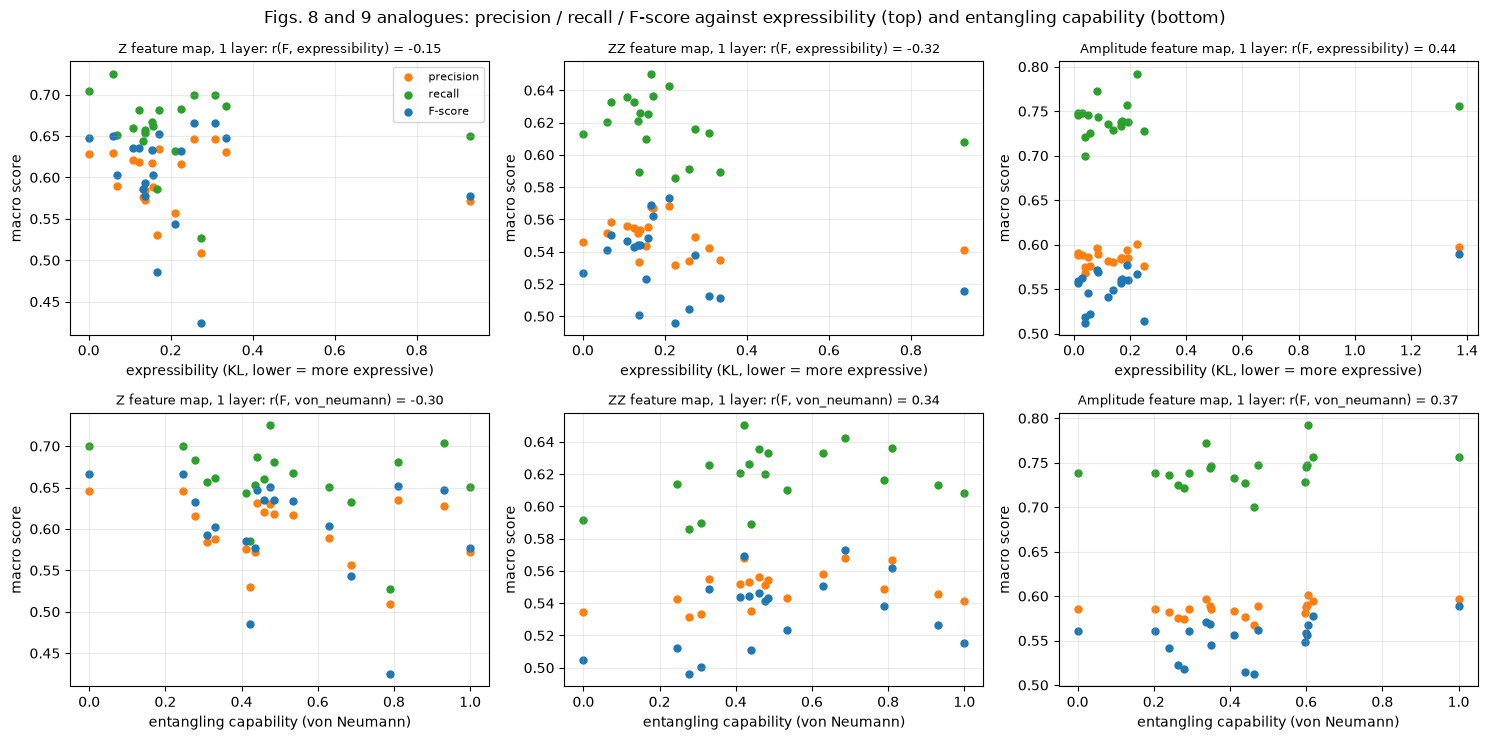

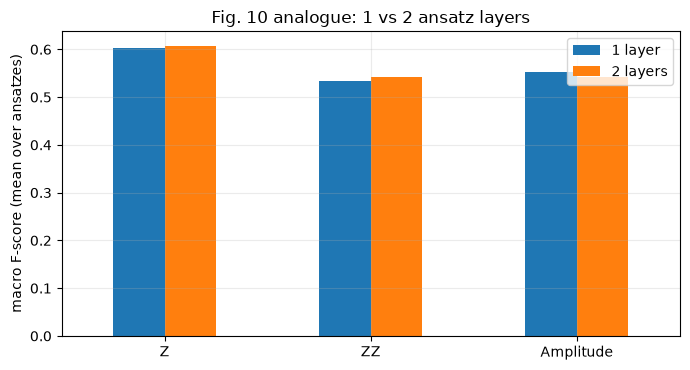

ansatzes whose macro F-score falls from 1 to 2 layers: {'Z': 9, 'ZZ': 8, 'Amplitude': 11} of 19


In [26]:
# ---- Pearson correlations between the ansatz quality metrics and the macro scores (the paper's Figs. 8 and 9) ----
def pear(x, y): return float(np.corrcoef(x, y)[0, 1]) if len(x) > 2 and np.std(x) > 0 and np.std(y) > 0 else np.nan
rows = []
for enc in ENCS:
    for layers in (1, 2):
        g = AG[(AG.encoding == enc) & (AG.layers == layers)]
        for mname in ("expressibility", "meyer_wallach", "von_neumann"):
            rows.append({"encoding": enc, "layers": layers, "metric": mname, "r(F-score)": pear(g[mname], g["macro_f1"]), "r(precision)": pear(g[mname], g["macro_prec"]), "r(recall)": pear(g[mname], g["macro_rec"])})
CORR = pd.DataFrame(rows)
CORR_AVG = CORR.groupby(["encoding", "metric"], sort=False)[["r(F-score)", "r(precision)", "r(recall)"]].mean()
print(f"Pearson correlation over the {len(ABL_ANSATZ)} ansatzes (per number of layers), and the mean over 1 and 2 layers:")
display(CORR.round(3)); display(CORR_AVG.round(3))
fig, ax = plt.subplots(2, 3, figsize=(15, 7.5))
for j, enc in enumerate(ENCS):
    g = AG[(AG.encoding == enc) & (AG.layers == 1)]
    for i, (mname, lab) in enumerate((("expressibility", "expressibility (KL, lower = more expressive)"), ("von_neumann", "entangling capability (von Neumann)"))):
        for col, c, nm in (("macro_prec", "tab:orange", "precision"), ("macro_rec", "tab:green", "recall"), ("macro_f1", "tab:blue", "F-score")):
            ax[i, j].scatter(g[mname], g[col], c=c, label=nm, s=25)
        ax[i, j].set_xlabel(lab); ax[i, j].set_ylabel("macro score"); ax[i, j].set_title(f"{enc} feature map, 1 layer: r(F, {mname}) = {pear(g[mname], g['macro_f1']):.2f}", fontsize=9)
ax[0, 0].legend(fontsize=8); plt.suptitle("Figs. 8 and 9 analogues: precision / recall / F-score against expressibility (top) and entangling capability (bottom)"); plt.tight_layout(); plt.show()
# Fig. 10 analogue: layers
L = AG.pivot_table(index="ansatz", columns=["encoding", "layers"], values="macro_f1")
fig, ax = plt.subplots(figsize=(7, 3.8))
pd.DataFrame({e: [L[(e, 1)].mean(), L[(e, 2)].mean()] for e in ENCS}, index=["1 layer", "2 layers"]).T.plot.bar(ax=ax, rot=0, color=["tab:blue", "tab:orange"])
ax.set_ylabel("macro F-score (mean over ansatzes)"); ax.set_title("Fig. 10 analogue: 1 vs 2 ansatz layers"); plt.tight_layout(); plt.show()
DROPS = {e: int((L[(e, 2)] < L[(e, 1)]).sum()) for e in ENCS}
print("ansatzes whose macro F-score falls from 1 to 2 layers:", DROPS, "of", len(ABL_ANSATZ))

## 9. Side-by-side comparison with the paper

Verdict rule (as for every notebook in this repository): a number is **reproduced** when it lies within 0.02 F1 (2 points) of the paper's value,
**exceeded** / **not reached** when it is more than 0.02 above / below, and **cannot be checked** when the paper gives no value or needs hardware / data that are
not available. Table 2 of the paper has scores that imply a balanced test set (a macro F1 equal to the phishing F1), so the notebook's `bal_*` columns (mean over
`N_BAL_DRAWS` random 150 + 150 subsets of the test set) are the primary matching quantities; the full 1:10 test set is shown beside them. Statements without
numbers (the textual claims about Figs. 5 to 7) get a verdict from the notebook's own numbers, with the evidence in the `notebook` column.

In [27]:
D = pd.DataFrame(RES)
def gv(model, col, kind=None):
    d = D[D["model"] == model]
    if kind: d = d[d["kind"] == kind]
    return float(d[col].mean()) if len(d) else np.nan
def verdict(paper, mine, tol=0.02):
    if mine is None or np.isnan(mine): return "cannot be checked"
    return "reproduced" if abs(mine - paper) <= tol else (f"exceeded (+{mine - paper:.2f})" if mine > paper else f"not reached ({mine - paper:+.2f})")
CLAIMS = []
def claim(cid, text, paper, mine, ver): CLAIMS.append({"id": cid, "claim": text, "paper": paper, "notebook": mine, "verdict": ver})

# ---- C0: Table 1 ----
nT = int((T1["rel. diff"] < 1e-3).sum())
claim("C0", "Table 1: 14 feature means and 14 standard deviations of 1,160 phishing / 10,800 non-phishing nodes", "28 numbers", f"{nT} of {len(T1)} within 0.1 % (largest relative difference {T1['rel. diff'].max():.1e}; std with ddof=1)",
      "reproduced" if nT == len(T1) else f"not reached ({nT}/{len(T1)} within 0.1 %)")

# ---- C1: Table 2 simulator rows ----
T2 = [("VQC (statevector)", "VQC", 0.67, 0.63), ("VQC + LGBM stacking (statevector)", "VQC -> LGBM", 0.86, 0.86), ("QSVM-dwave = classical annealing", "QSVM-anneal", 0.78, 0.74)]
t2rows = []
for label, model, pm, pp in T2:
    for metric, col, pv in (("macro F1", "macro_f1", pm), ("phishing F1", "phish_f1", pp)):
        mb, mf = gv(model, "bal_" + col), gv(model, "full_" + col)
        claim("C1", f"Table 2: {label}, {metric}", pv, f"balanced {mb:.3f} | full test {mf:.3f}", f"{verdict(pv, mb)} (balanced); {verdict(pv, mf)} (full test)")
for label, pm, pp in (("VQC on ibmq_belem (5 qubits)", 0.61, 0.59), ("VQC on ibmq_geneva (27 qubits)", 0.64, 0.57), ("VQC + LGBM on ibmq_belem", 0.85, 0.85), ("VQC + LGBM on ibmq_mumbai", 0.85, 0.85), ("QSVM-dwave on the D-Wave 5617-qubit annealer", 0.78, 0.74)):
    claim("C1", f"Table 2 hardware row: {label}, macro F1 / phishing F1", f"{pm} / {pp}", "not run (no device)", "cannot be checked")

# ---- C2: gain of stacking VQC with LGBM ----
gain = gv("VQC -> LGBM", "bal_macro_f1") - gv("VQC", "bal_macro_f1")
claim("C2", "Stacking VQC with LGBM raises the macro F1 on the simulator by 0.19 (0.67 to 0.86); 0.24 on the noisy 5-qubit device", "+0.19 (simulator), +0.24 (device)",
      f"{gain:+.3f} (balanced: {gv('VQC', 'bal_macro_f1'):.3f} to {gv('VQC -> LGBM', 'bal_macro_f1'):.3f}); full test {gv('VQC -> LGBM', 'full_macro_f1') - gv('VQC', 'full_macro_f1'):+.3f}",
      f"{verdict(0.19, gain)} for the simulator gain; device gain cannot be checked")

# ---- C3: classical models better at recall, QSVM / VQC weaker ----
cls_rec = np.mean([gv(m, "full_phish_rec") for m in ("SVM-rbf", "LGBM", "RF")]); q_rec = np.mean([gv(m, "full_phish_rec") for m in ("QSVM", "VQC")])
claim("C3", "Classical models are better at recall than QSVM-qiskit and VQC (full test set, phishing recall)", "classical > QSVM, VQC",
      f"SVM {gv('SVM-rbf', 'full_phish_rec'):.3f}, LGBM {gv('LGBM', 'full_phish_rec'):.3f}, RF {gv('RF', 'full_phish_rec'):.3f} vs QSVM {gv('QSVM', 'full_phish_rec'):.3f}, VQC {gv('VQC', 'full_phish_rec'):.3f}",
      "reproduced" if cls_rec > q_rec else f"not reached: mean recall classical {cls_rec:.3f} vs QSVM/VQC {q_rec:.3f}")
claim("C3", "QSVM-qiskit and VQC are weaker classifiers than the classical models (full-test macro F1 below LGBM)", "QSVM, VQC < classical",
      f"LGBM {gv('LGBM', 'full_macro_f1'):.3f}, RF {gv('RF', 'full_macro_f1'):.3f}, SVM {gv('SVM-rbf', 'full_macro_f1'):.3f} vs QSVM {gv('QSVM', 'full_macro_f1'):.3f}, VQC {gv('VQC', 'full_macro_f1'):.3f}",
      "reproduced" if max(gv("QSVM", "full_macro_f1"), gv("VQC", "full_macro_f1")) < gv("LGBM", "full_macro_f1") else "not reached")

# ---- C4: false positives of QSVM-qiskit ----
fps = {m: gv(m, "full_FP") for m in ("SVM-rbf", "LGBM", "RF", "QSVM", "VQC", "QSVM-anneal")}
claim("C4", "QSVM-qiskit has the fewest false positives of the individual models (Fig. 7)", "QSVM-qiskit lowest FP", "; ".join(f"{k} {v:.0f}" for k, v in fps.items()),
      "reproduced" if fps["QSVM"] <= min(fps.values()) else f"not reached: {min(fps, key=fps.get)} has fewer false positives")
a = ST[ST["has_qsvm_qiskit"] & ~ST["has_anneal"]]["full_FP"]; b = ST[~ST["has_qsvm_qiskit"] & ~ST["has_anneal"]]["full_FP"]
claim("C4", "Ensembles containing QSVM-qiskit (without QSVM-dwave) have fewer false positives than those without it", "fewer FP / more TN",
      f"mean FP {a.mean():.0f} (n={len(a)}) vs {b.mean():.0f} (n={len(b)})", "reproduced" if a.mean() < b.mean() else "not reached")

# ---- C5: annealing QSVM ----
qm = {m: gv(m, "full_macro_f1") for m in ("QSVM", "VQC", "QSVM-anneal")}; qb = {m: gv(m, "bal_macro_f1") for m in ("QSVM", "VQC", "QSVM-anneal")}
claim("C5", "QSVM-dwave (annealing) has the best macro F-score of the quantum models", "annealing best", f"full test {qm}; balanced {qb}".replace("'", ""),
      "reproduced" if qm["QSVM-anneal"] >= max(qm.values()) else f"not reached: {max(qm, key=qm.get)} is best on the full test set" + ("; annealing best on the balanced draws" if qb["QSVM-anneal"] >= max(qb.values()) else ""))
tq = {m: gv(m, "t_s", "single") for m in ("QSVM", "VQC", "QSVM-anneal")}
claim("C5", "QSVM-dwave is the fastest to train of the quantum models (wall-clock here: exact simulation, simulated annealing)", "annealing fastest", "; ".join(f"{k} {v:.1f}s" for k, v in tq.items()),
      "reproduced" if tq["QSVM-anneal"] <= min(tq.values()) else f"not reached: {min(tq, key=tq.get)} is fastest here (annealing is simulated on a CPU)")
an = ST[ST["bases"].str.split("+").apply(lambda l: "QSVM-anneal" in l)]; alone = gv("QSVM-anneal", "full_macro_f1")
dd = (an["full_macro_f1"] - alone).abs()
claim("C5", "Stacked with QSVM-dwave as a base model, the ensemble gives the same result as QSVM-dwave alone", "ensemble = QSVM-dwave alone",
      f"{len(an)} ensembles with QSVM-dwave as a base: mean |macro-F1 difference to QSVM-dwave alone ({alone:.3f})| = {dd.mean():.3f}, {int((dd <= 0.02).sum())} within 0.02",
      "reproduced" if dd.mean() <= 0.02 else f"not reached (mean difference {dd.mean():.3f}; {int((dd <= 0.02).sum())} of {len(an)} within 0.02)")

# ---- C6: ensembles ----
top10 = ST.head(10); best_ind = single["full_macro_f1"].idxmax()
claim("C6", "All of the 10 best ensembles contain at least one quantum model", "10 of 10", f"{int(top10['has_quantum'].sum())} of 10 (top-10 by macro F1 on the full test set; chosen on the test set)",
      "reproduced" if top10["has_quantum"].all() else f"not reached ({int(top10['has_quantum'].sum())}/10)")
claim("C6", "Ensembles improve the macro F-score over the individual models", "ensemble > best individual", f"best ensemble {ST['full_macro_f1'].max():.3f} ({ST['full_macro_f1'].idxmax()}) vs best individual {single['full_macro_f1'].max():.3f} ({best_ind}); median ensemble {ST['full_macro_f1'].median():.3f}, median individual {single['full_macro_f1'].median():.3f}",
      "reproduced" if ST["full_macro_f1"].max() > single["full_macro_f1"].max() else "not reached")
claim("C6", "Ensembles improve the phishing F-score over the individual models", "ensemble > best individual", f"best ensemble {ST['full_phish_f1'].max():.3f} vs best individual {single['full_phish_f1'].max():.3f}",
      "reproduced" if ST["full_phish_f1"].max() > single["full_phish_f1"].max() else "not reached")
if OOF_STACKS:
    so_best = SO["full_macro_f1"].max()
    claim("C6", "(extra, honest variant) the same with out-of-fold base labels, which remove the in-sample optimism of the base labels", "-", f"best out-of-fold ensemble {so_best:.3f} vs best individual {single['full_macro_f1'].max():.3f}; median {SO['full_macro_f1'].median():.3f}",
          "reproduced" if so_best > single["full_macro_f1"].max() else "not reached")

# ---- C7: bagging ----
dbag = D[D["kind"] == "bag"]; mem = D[D["kind"] == "bag-member"]
for model in ("QSVM", "VQC", "QSVM-anneal"):
    bg = dbag[dbag["model"] == f"bagging {model}: max voting"]["full_macro_f1"].mean(); bw = dbag[dbag["model"] == f"bagging {model}: F1-weighted"]["full_macro_f1"].mean()
    mm_ = mem[mem["model"] == f"bag member: {model}"]["full_macro_f1"].mean(); one = gv(model, "full_macro_f1", "single")
    claim("C7", f"Bagging {model} brings no significant improvement over the individual runs (full-test macro F1)", "|gain| small", f"max voting {bg:.3f}, weighted {bw:.3f} vs mean of the 5 members {mm_:.3f} (standard model {one:.3f})",
          "reproduced" if max(abs(bg - mm_), abs(bw - mm_)) <= 0.02 else (f"not reached: bagging changes the macro F1 by {bg - mm_:+.3f} / {bw - mm_:+.3f}"))

# ---- C8: timing ----
sq, sv = slopes["QSVM (this notebook) s"], slopes["VQC (this notebook) s"]
claim("C8", "QSVM-qiskit training time grows about linearly with the training size", "linear (slope ~1)", f"log-log slope {sq:.2f} for sizes {SCALE_SIZES[0]} to {SCALE_SIZES[-1]}" + (f"; Qiskit QSVC slope {slopes['QSVC (Qiskit) s']:.2f}" if "QSVC (Qiskit) s" in slopes else ""),
      "reproduced" if 0.7 <= sq <= 1.3 else f"not reached (slope {sq:.2f})")
claim("C8", "VQC training time grows faster than the QSVM's", "VQC slope > QSVM slope", f"VQC slope {sv:.2f}, QSVM slope {sq:.2f}; at n={SCALE_SIZES[-1]}: VQC {TT['VQC (this notebook) s'].iloc[-1]:.2f}s vs QSVM {TT['QSVM (this notebook) s'].iloc[-1]:.2f}s",
      "reproduced" if sv > sq else f"not reached (VQC slope {sv:.2f} <= QSVM slope {sq:.2f}; with a fixed COBYLA budget the VQC cost is linear in n)")
claim("C8", "Absolute times at 20,000 training nodes (QSVM 1,389 s, VQC 56,903 s)", "1,389 s / 56,903 s", "the data file holds only 960 training nodes", "cannot be checked")

# ---- C9: ansatz correlations ----
PAPER_R = {("Z", "expressibility"): -0.720, ("ZZ", "expressibility"): -0.71295, ("Amplitude", "expressibility"): -0.8413,
           ("Z", "von_neumann"): -0.940, ("ZZ", "von_neumann"): -0.919, ("Amplitude", "von_neumann"): -0.940}
for (enc, mname), pv in PAPER_R.items():
    r_ = CORR_AVG.loc[(enc, mname), "r(F-score)"]
    claim("C9", f"Pearson r of the macro F-score with {mname.replace('_', ' ')}, {enc} feature map (mean over 1 and 2 layers)", pv, f"{r_:.3f} over {len(ABL_ANSATZ)} ansatzes",
          verdict(pv, r_) + ("" if np.isnan(r_) or np.sign(r_) == np.sign(pv) else "; sign differs"))
rr = CORR_AVG.xs("expressibility", level="metric")["r(recall)"]
claim("C9", "Recall shows no significant change with expressibility (|r| small)", "no significant change", "r(recall, expressibility) = " + ", ".join(f"{e} {v:.2f}" for e, v in rr.items()),
      "reproduced" if (rr.abs() < 0.3).all() else "not reached: " + ", ".join(f"{e} {v:.2f}" for e, v in rr.items() if abs(v) >= 0.3))
rp = CORR_AVG.xs("von_neumann", level="metric")
claim("C9", "Entangling capability correlates more strongly (negatively) with precision and F-score than expressibility does", "|r(entangling)| > |r(expressibility)|",
      "r(F, entangling) = " + ", ".join(f"{e} {v:.2f}" for e, v in rp["r(F-score)"].items()) + " vs r(F, expressibility) = " + ", ".join(f"{e} {v:.2f}" for e, v in CORR_AVG.xs("expressibility", level="metric")["r(F-score)"].items()),
      "reproduced" if (rp["r(F-score)"].abs().values > CORR_AVG.xs("expressibility", level="metric")["r(F-score)"].abs().values).all() else "not reached for at least one feature map")

# ---- C10: layers ----
claim("C10", "Macro F-score falls from 1 to 2 ansatz layers for all 19 circuits and all 3 feature maps", "19 of 19, three times", f"falls for {DROPS} of {len(ABL_ANSATZ)} ansatzes",
      "reproduced" if all(v == len(ABL_ANSATZ) for v in DROPS.values()) else f"not reached: {DROPS}")

CL = pd.DataFrame(CLAIMS)
pd.set_option("display.max_colwidth", 200, "display.width", 250, "display.max_rows", 300)
display(CL)
CL["v"] = CL["verdict"].str.extract(r"^(reproduced|exceeded|not reached|cannot be checked)")[0].fillna("mixed")
print("verdict counts:", CL["v"].value_counts().to_dict())

,id,claim,paper,notebook,verdict
0,C0,"Table 1: 14 feature means and 14 standard deviations of 1,160 phishing / 10,800 non-phishing nodes",28 numbers,28 of 28 within 0.1 % (largest relative difference 4.3e-04; std with ddof=1),reproduced
1,C1,"Table 2: VQC (statevector), macro F1",0.67,balanced 0.624 | full test 0.556,not reached (-0.05) (balanced); not reached (-0.11) (full test)
2,C1,"Table 2: VQC (statevector), phishing F1",0.63,balanced 0.571 | full test 0.264,not reached (-0.06) (balanced); not reached (-0.37) (full test)
3,C1,"Table 2: VQC + LGBM stacking (statevector), macro F1",0.86,balanced 0.940 | full test 0.815,exceeded (+0.08) (balanced); not reached (-0.04) (full test)
4,C1,"Table 2: VQC + LGBM stacking (statevector), phishing F1",0.86,balanced 0.941 | full test 0.678,exceeded (+0.08) (balanced); not reached (-0.18) (full test)
5,C1,"Table 2: QSVM-dwave = classical annealing, macro F1",0.78,balanced 0.761 | full test 0.758,reproduced (balanced); not reached (-0.02) (full test)
6,C1,"Table 2: QSVM-dwave = classical annealing, phishing F1",0.74,balanced 0.718 | full test 0.561,not reached (-0.02) (balanced); not reached (-0.18) (full test)
7,C1,"Table 2 hardware row: VQC on ibmq_belem (5 qubits), macro F1 / phishing F1",0.61 / 0.59,not run (no device),cannot be checked
8,C1,"Table 2 hardware row: VQC on ibmq_geneva (27 qubits), macro F1 / phishing F1",0.64 / 0.57,not run (no device),cannot be checked
9,C1,"Table 2 hardware row: VQC + LGBM on ibmq_belem, macro F1 / phishing F1",0.85 / 0.85,not run (no device),cannot be checked


verdict counts: {'not reached': 14, 'reproduced': 10, 'exceeded': 9, 'cannot be checked': 6}


## 10. Reading the paper critically

All numbers below are from the saved full run (`FAST_MODE = False`); the verdict table of Section 9 has the details.

**What reproduced.** Table 1 (the feature statistics) matches the authors' files to 0.1 % in all 28 entries (sample standard deviation), so the files are the paper's data. The annealing QSVM
reproduces its Table 2 row on balanced test sets (macro F1 0.761 against 0.78). The textual statements that classical models are better at recall than QSVM-qiskit and VQC (not quite: QSVM-qiskit has
the highest recall of all, 0.981, but it buys it with 2,377 false positives) and that both quantum models are the weaker classifiers hold. QSVM-dwave is the best quantum model, and bagging changes
nothing for QSVM and QSVM-dwave.

**What did not.**
* *The headline of Table 2, "VQC + LGBM: 0.67 to 0.86", is a statement about LightGBM, not about the VQC.* On the same balanced draws LightGBM alone scores 0.945 macro F1 and the
  VQC-then-LGBM stack 0.940: stacking the VQC on top of LightGBM gives no gain and a slightly lower score. The table compares the stack with the VQC alone but not with LightGBM alone, which is the
  control that matters. On the realistic 1:10 test set the best ensemble (0.821) equals the best individual model (LightGBM, 0.821), the median ensemble (0.728) is *below* the median individual
  model (0.743), and the out-of-fold variant (0.823 at best) is no different. The paper's claim that ensembles improve the macro and phishing F-scores is therefore not reproduced here. That all
  top-10 ensembles contain a quantum model is also not reproduced (7 of 10): the classical and the quantum-assisted stacks differ by about 0.001 and their order is noise.
* *Selection on the test set.* "Best ensembles" are picked out of 57 by their test score; the whole distribution (Section 4) is the honest picture.
* *In-sample base labels.* As in the authors' notebooks, a base model labels its own training nodes before the meta classifier is trained. A model that memorises its training data (LightGBM
  does) then looks perfectly reliable to the meta classifier. The out-of-fold variant removes this and changes little here, but it is the safer design.
* *QSVM-qiskit and false positives.* The paper's strongest quantum claim is that QSVM-qiskit has the fewest false positives. With the ZZ feature map on the raw features (what the authors' notebooks
  do) it has the most (2,377 of 10,000 non-phishing nodes), because raw degree and strength values of thousands are used as rotation angles and wrap around many times. The sibling notebook for
  Ray et al. 2023 (`QRAC_EthereumPhishing_Ray2023.ipynb`) shows how much the encoding matters.
* *The VQC is close to chance on this encoding* (macro F1 0.556 on the full test set, 0.62 on balanced draws, after 100 COBYLA iterations with 42 weights), and the "last bit" read-out of Qiskit's own `VQC`
  class is no better (0.54). With all 19 ansatzes the macro F-score moves between about 0.43 and 0.67 with the random start, which is as large as the differences the paper interprets.
* *The ansatz study (Figs. 8 to 10) was not reproduced.* Pearson correlations of the F-score with expressibility and with the entangling capability are -0.17 / -0.11 / +0.20 and -0.05 / +0.20 / +0.27 for
  the Z, ZZ and amplitude maps (paper: -0.72 / -0.71 / -0.84 and -0.94 / -0.92 / -0.94), and the F-score falls from one to two layers for only 9, 8 and 11 of the 19 ansatzes (paper: all 19). Reasons
  worth separating: only two runs per configuration here (paper: five); the 19 ansatzes are re-implemented from a figure; the expressibility sign convention (the paper's narrative treats a *larger*
  value as more expressive, Sim et al. define the KL divergence, where smaller means more expressive); and, above all, a VQC whose scores differ by little more than its run-to-run noise leaves
  nothing for a correlation to find.
* *Scaling (Fig. 4).* The QSVM time grows with a log-log slope of about 1.1 up to 960 nodes (Qiskit's `QSVC`: 1.2), consistent with "about linear" at these sizes (the kernel is quadratic
  asymptotically); the VQC with a fixed 100-iteration budget does not grow faster here (slope 0.4), so the paper's "VQC grows polynomially" is not seen at 960 nodes. 20,000 nodes were out of reach.
* *Class imbalance.* The paper stresses that phishing is 1 in 2,500 nodes, but evaluates on a 1:10 test set (and Table 2 apparently on a balanced one). At the true prevalence, LightGBM's false-positive rate
  on the non-phishing nodes (849 of 10,000, 8.5 %) would give a precision of well under 1 %.
* *Not checkable here:* the hardware rows (belem, geneva, mumbai, D-Wave), the GCN, the three-level stack with a GCN (a classical stand-in gives 0.81 to 0.82), and the 20 K-node timings.

## 11. Exercises

1. **Out-of-fold everywhere.** The notebook runs the out-of-fold variant for the first run only. Switch it on for both runs and for the bagging weights (compute the weights on out-of-bag nodes) and
   check whether any ensemble beats LightGBM alone on a held-out *validation* split rather than on the test set.
2. **Fix the encoding.** Replace the raw features by `log1p` then `MinMaxScaler((0, pi))` (fitted on the training split) for the QSVM and the VQC, rerun Sections 3 to 5 and compare the false positives of QSVM
   with the 2,377 above. Which claims of the paper become true?
3. **Prevalence.** Recompute precision and phishing F1 for every individual model and for the best stacks after re-weighting the test set to a phishing prevalence of 1 in 100 and 1 in 2,500.
   Which model would an analyst rather use?
4. **A better VQC study.** Give the VQC more iterations or another optimiser (SPSA), use 5 runs per configuration as in the paper (`ABL_RUNS = 5`, `ABL_MAXITER = 300`), and test whether the correlations of Section 8
   appear once the VQC is clearly better than chance. Also try the expressibility with a negated sign.
5. **Quantum meta classifiers.** Add more entries to `VQC_META_STACKS` (8- and 9-qubit VQC as meta classifier) and compare them with the classical meta classifiers; how much does the training time grow
   with every appended qubit (see the circuit table in Section 2)?
